# TP — Chaînes de déploiement d'un modèle d'IA
## Pipeline GPU n°1 : PyTorch → ONNX → TensorRT → CUDA/cuDNN → GPU

| Niveau | Composant | Rôle dans ce notebook |
|---|---|---|
| **Haut niveau** | PyTorch | ResNet-18 pré-entraîné ImageNet, tête 10 classes (section 1, commune aux 4 notebooks) |
| **Format du modèle** | ONNX | le **même fichier ONNX** que le pipeline CPU n°1 (`shared/resnet18_cifar10.onnx`) |
| **Middle level** | TensorRT | parsing ONNX, fusion d'opérateurs, choix des kernels (*tactics*) chronométrés sur ce GPU, FP32 et FP16 (4.2–4.3) |
| **Bas niveau** | CUDA, cuDNN / cuBLAS, kernels TensorRT | kernels réellement exécutés, visibles par profilage (4.5) |
| **Matériel** | GPU de Google Colab | NVIDIA T4 (Turing, Tensor Cores FP16), environnement d'exécution « GPU » |

**Modèle** : ResNet-18 pré-entraîné ImageNet, 10 classes · **Données** : 50 images de test CIFAR-10 (5 par classe) · **Batch** : 10 · **Répétitions** : 10 passes mesurées + 3 mesures d'énergie — **même protocole et mêmes fichiers que les notebooks CPU**.

### Avant de lancer
1. `Exécution` → `Modifier le type d'exécution` → **GPU T4**. Utiliser le même GPU pour le notebook GPU n°2.
2. `Exécution` → `Tout exécuter` et autoriser l'accès à **votre** Google Drive : le dossier `MyDrive/TP_Deploiement_IA` est créé et partagé entre vos deux notebooks GPU. Le premier notebook lancé crée les 50 images, la tête 10 classes et le fichier ONNX **avec le même code et la même graine que les notebooks CPU** ; le second les recharge.
3. Pour la comparaison des 4 pipelines (section 6) : importer les résultats envoyés par le binôme CPU, puis envoyer les vôtres avec la dernière cellule.
4. Durée : ≈ 10 min (+ ≈ 3 min au premier lancement pour la tête 10 classes, calculée sur CPU comme dans les notebooks CPU ; dont ≈ 1–2 min de construction des moteurs TensorRT), + ≈ 5 min pour l'étude optionnelle des tailles de batch.

### Plan
0. Environnement · 1. Préparation commune · 2. Outils de mesure · 3. Référence PyTorch eager GPU · 4. Pipeline ONNX → TensorRT · 5. Résultats de ce pipeline · 6. Comparaison des 4 pipelines · 7. Analyse

## 0. Environnement
### 0.1 Installation
`tensorrt` (wheel correspondant à la version CUDA de PyTorch), `onnx` / `onnxscript` (export, si le fichier ONNX n'existe pas encore), `nvidia-ml-py` (NVML : mesure de l'énergie GPU), `psutil`.

In [5]:
import torch
CUDA_MAJOR = torch.version.cuda.split(".")[0] if torch.version.cuda else "12"
print("CUDA utilisé par PyTorch :", torch.version.cuda, "→ paquet tensorrt-cu" + CUDA_MAJOR)
!pip install -q onnx onnxscript nvidia-ml-py psutil
!pip install -q "tensorrt-cu{CUDA_MAJOR}" || pip install -q tensorrt
!nvidia-smi --query-gpu=name,driver_version,memory.total,power.limit --format=csv

CUDA utilisé par PyTorch : 13.0 → paquet tensorrt-cu13
name, driver_version, memory.total [MiB], power.limit [W]
Tesla T4, 580.82.07, 15360 MiB, 70.00 W


### 0.2 Configuration de l'expérience
Les paramètres expérimentaux sont **identiques dans les 4 notebooks** (images, batch, warm-up, répétitions, énergie) : ce bloc est le même que dans les notebooks CPU, seuls le nom de la session et la vérification du matériel changent.

In [6]:
import os, json, time, math, copy, hashlib, datetime, warnings
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F, torchvision
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=UserWarning)

# ---------- Paramètres expérimentaux : IDENTIQUES dans les deux notebooks ----------
SEED = 42
N_IMAGES = 50            # images de test CIFAR-10
BATCH_SIZE = 10          # => 5 batches par passe
N_WARMUP = 5             # passes complètes non mesurées
N_RUNS = 10              # passes mesurées (>= 3 exigées)
ENERGY_MIN_SECONDS = 10.0
N_ENERGY_REPS = 3
N_THREADS = os.cpu_count()          # tous les vCPU, pour chaque moteur
CPU_POWER_PER_VCPU_W = 10.0         # HYPOTHÈSE utilisée seulement si RAPL est inaccessible

# ---------- Adaptation du modèle à 10 classes (si les poids n'existent pas encore) ----------
N_TRAIN_PER_CLASS = 300  # images d'entraînement par classe pour le linear probing
N_VAL = 500              # images de test (hors des 50) pour estimer la précision du modèle

# ---------- Stockage partagé par les deux notebooks (Google Drive) ----------
USE_DRIVE = True         # votre propre Google Drive : partage les fichiers entre vos 2 notebooks GPU
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/TP_Deploiement_IA"
else:
    ROOT = "/content/TP_Deploiement_IA"
SHARED, RESULTS, FIGS, WORK = f"{ROOT}/shared", f"{ROOT}/results", f"{ROOT}/figures", "/content/work"
for d in (SHARED, RESULTS, FIGS, WORK):
    os.makedirs(d, exist_ok=True)

PIPELINE_TAG = "trt"
SESSION_ID = PIPELINE_TAG + "_" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
torch.manual_seed(SEED); np.random.seed(SEED)
torch.set_num_threads(N_THREADS)
# ---------- Spécifique GPU ----------
assert torch.cuda.is_available(), "Aucun GPU : Exécution → Modifier le type d'exécution → GPU (T4)"
DEVICE = torch.device("cuda")
torch.backends.cudnn.benchmark = True   # cuDNN choisit le meilleur algorithme de convolution pour la forme d'entrée
print("Session :", SESSION_ID, "| GPU :", torch.cuda.get_device_name(0), "| dossier :", ROOT)

RUN_FP16 = True          # variante TensorRT FP16 (Tensor Cores)
RUN_BATCH_STUDY = True   # étude complémentaire batch 1 / 10 / 50 (hors protocole commun, non utilisée dans la comparaison)
SESSION_REF_KEY = "gpu_trt_ref_eager"

Mounted at /content/drive
Session : trt_20261125-163952 | GPU : Tesla T4 | dossier : /content/drive/MyDrive/TP_Deploiement_IA


### (Optionnel) Sans Google Drive : importer l'archive produite par l'autre notebook
Seulement si `USE_DRIVE = False` et que l'autre notebook a déjà été exécuté : importez `TP_Deploiement_IA.zip` (dernière cellule de l'autre notebook). Sinon, ignorez cette cellule.

In [7]:
if not USE_DRIVE and not os.path.exists(f"{SHARED}/cifar10_test50.pt"):
    import zipfile
    from google.colab import files
    print("Importez TP_Deploiement_IA.zip (ou annulez si c'est le premier notebook exécuté).")
    try:
        up = files.upload()
        with zipfile.ZipFile(next(iter(up))) as z:
            z.extractall(ROOT)
    except Exception as e:
        print("Aucune archive importée :", e)

### (Optionnel) Utiliser exactement les fichiers de votre binôme
Par défaut, la section 1 **recrée** les 50 images et la tête 10 classes avec **le même code et la même graine** que les notebooks CPU : on obtient les mêmes indices d'images (vérifiables dans l'affichage de la section 1) et un modèle équivalent. Si votre binôme peut vous envoyer ses fichiers `cifar10_test50.pt` et `resnet18_cifar10.pth` (dossier `shared` de son Drive), mettez `IMPORT_SHARED_FROM_PARTNER = True` : ils seront utilisés tels quels et les modèles seront **strictement identiques** sur les 4 pipelines.

In [8]:
IMPORT_SHARED_FROM_PARTNER = False
if IMPORT_SHARED_FROM_PARTNER:
    from google.colab import files
    print("Sélectionnez cifar10_test50.pt et resnet18_cifar10.pth (et éventuellement resnet18_cifar10.onnx, model_info.json)")
    for name, data in files.upload().items():
        base = os.path.basename(name).split(" (")[0]          # Colab renomme parfois en « fichier (1).pt »
        if base in ("cifar10_test50.pt", "resnet18_cifar10.pth", "resnet18_cifar10.onnx", "model_info.json"):
            with open(f"{SHARED}/{base}", "wb") as f:
                f.write(data)
            print("  →", f"{SHARED}/{base}")

### 0.3 Informations sur l'environnement (enregistrées avec chaque résultat)

In [9]:
import os, platform, subprocess

def _cpu_model():
    try:
        with open("/proc/cpuinfo") as f:
            for line in f:
                if line.startswith("model name"):
                    return line.split(":", 1)[1].strip()
    except Exception:
        pass
    return platform.processor()

def get_env_info():
    import torch, torchvision
    info = {"python": platform.python_version(), "torch": torch.__version__,
            "torchvision": torchvision.__version__, "cpu": _cpu_model(), "n_vcpu": os.cpu_count(),
            "torch_threads": torch.get_num_threads()}
    if torch.cuda.is_available():
        info.update({"cuda": torch.version.cuda, "cudnn": torch.backends.cudnn.version(),
                     "gpu": torch.cuda.get_device_name(0),
                     "compute_capability": ".".join(map(str, torch.cuda.get_device_capability(0)))})
        try:
            info["nvidia_driver"] = subprocess.check_output(
                ["nvidia-smi", "--query-gpu=driver_version", "--format=csv,noheader"]).decode().strip()
        except Exception:
            pass
    return info

ENV = get_env_info()
FAILED = {}   # variantes qui ont échoué (le notebook continue sans elles ; résumé à la fin)
try:
    import tensorrt as trt
    ENV["tensorrt"] = trt.__version__
    TRT_OK = True
except Exception as e:
    TRT_OK = False
    FAILED["TensorRT (import)"] = repr(e)
    print("⚠ TensorRT n'a pas pu être importé :", repr(e), "\n  → relancez la cellule d'installation, puis « Tout exécuter ».")
import onnx
ENV["onnx"] = onnx.__version__
for k, v in ENV.items():
    print(f"{k:>20} : {v}")

              python : 3.13.16
               torch : 2.14.1+cu130
         torchvision : 0.29.1+cu130
                 cpu : Intel(R) Xeon(R) CPU @ 2.00GHz
              n_vcpu : 2
       torch_threads : 2
                cuda : 13.0
               cudnn : 92800
                 gpu : Tesla T4
  compute_capability : 7.5
       nvidia_driver : 580.82.07
            tensorrt : 11.5.0.63
                onnx : 1.23.2


## 1. Préparation commune : modèle et données (identique dans les deux notebooks)

Cette section est **la même dans les deux notebooks**. Le premier notebook exécuté crée les fichiers dans `Drive/TP_Deploiement_IA/shared` ; le second les **recharge** au lieu de les recréer. Les deux pipelines utilisent donc exactement le même modèle et les mêmes octets d'entrée (contrôle par empreinte SHA-256).

**Données** : 50 images du jeu de **test** CIFAR-10, tirées avec une graine fixe, **5 par classe** (sous-ensemble équilibré).

**Prétraitement** (fonction unique `preprocess_uint8`) :
1. `uint8 [0,255]` → `float32 [0,1]` ;
2. redimensionnement **32×32 → 224×224** (bilinéaire), résolution d'entraînement de ResNet-18 ;
3. normalisation avec les statistiques ImageNet du pré-entraînement : `mean=(0.485, 0.456, 0.406)`, `std=(0.229, 0.224, 0.225)`.

**Modèle à 10 classes** : ResNet-18 pré-entraîné ImageNet sort 1000 classes. On garde tout le réseau pré-entraîné **gelé** et on remplace la dernière couche `fc` (512 → 1000) par une couche 512 → 10 apprise sur des images d'**entraînement** CIFAR-10 (*linear probing*, ≈ 2–3 min sur CPU). Si un fichier de poids existe déjà dans `shared` (par exemple créé par le notebook GPU d'un binôme), il est réutilisé tel quel.

In [10]:
# Téléchargement rapide de CIFAR-10 (miroir Hugging Face ; torchvision vérifie le MD5 officiel)
import os, hashlib
P = "/content/data/cifar-10-python.tar.gz"
MD5_OK = "c58f30108f718f92721af3b95e74349a"
os.makedirs("/content/data", exist_ok=True)
if os.path.exists(P) and hashlib.md5(open(P, "rb").read()).hexdigest() != MD5_OK: os.remove(P)
if not os.path.exists(P): os.system(f"wget -q -O {P} https://huggingface.co/cloneofsimo/test_model/resolve/main/cifar-10-python.tar.gz")
print("MD5 :", hashlib.md5(open(P, "rb").read()).hexdigest(), "| attendu :", MD5_OK)

MD5 : c58f30108f718f92721af3b95e74349a | attendu : c58f30108f718f92721af3b95e74349a


In [11]:
# ---------- Modèle et prétraitement (définitions communes) ----------
from torchvision.models import resnet18, ResNet18_Weights

NUM_CLASSES = 10
IMG_SIZE = 224
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

def build_model(num_classes=NUM_CLASSES, pretrained=True):
    m = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
    m.fc = nn.Linear(m.fc.in_features, num_classes)
    return m

def preprocess_uint8(x_uint8_nhwc):
    # uint8 [N,32,32,3] -> float32 [N,3,224,224] normalisé ImageNet
    x = x_uint8_nhwc.permute(0, 3, 1, 2).float().div(255.0)
    x = F.interpolate(x, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)
    mean = torch.tensor(MEAN, device=x.device).view(1, 3, 1, 1)
    std = torch.tensor(STD, device=x.device).view(1, 3, 1, 1)
    return (x - mean) / std

PREPROCESSING = {"resize": [IMG_SIZE, IMG_SIZE], "interpolation": "bilinear, align_corners=False",
                 "scale": "1/255", "mean": list(MEAN), "std": list(STD), "layout": "NCHW float32"}

TEST50_PATH = f"{SHARED}/cifar10_test50.pt"
WEIGHTS_PATH = f"{SHARED}/resnet18_cifar10.pth"
MODEL_INFO_PATH = f"{SHARED}/model_info.json"
ONNX_PATH = f"{SHARED}/resnet18_cifar10.onnx"

train_set = torchvision.datasets.CIFAR10("/content/data", train=True, download=True)
test_set = torchvision.datasets.CIFAR10("/content/data", train=False, download=True)
CLASSES = test_set.classes

Sous-ensemble créé : /content/drive/MyDrive/TP_Deploiement_IA/shared/cifar10_test50.pt
Images : (50, 3, 224, 224) torch.float32 | par classe : [5 5 5 5 5 5 5 5 5 5]
Indices CIFAR-10 (test) : [347, 883, 1020, 1216, 1381, 1626, 1658, 1870, 2285, 2786, 3138, 3316, 3534, 3802, 4064, 4244, 4297, 4374, 4426, 4492, 4542, 4589, 4609, 4623, 4811, 5052, 5217, 5486, 5501, 6056, 6274, 6574, 6733, 6999, 7075, 7450, 7527, 7638, 7662, 7701, 8118, 8181, 8363, 8430, 8452, 8901, 9149, 9651, 9652, 9763]
SHA-256 des entrées : 117a8d622a1424ccdda5f77c957bd3794f6b3a54ff4d94a690b53d19052a30f9


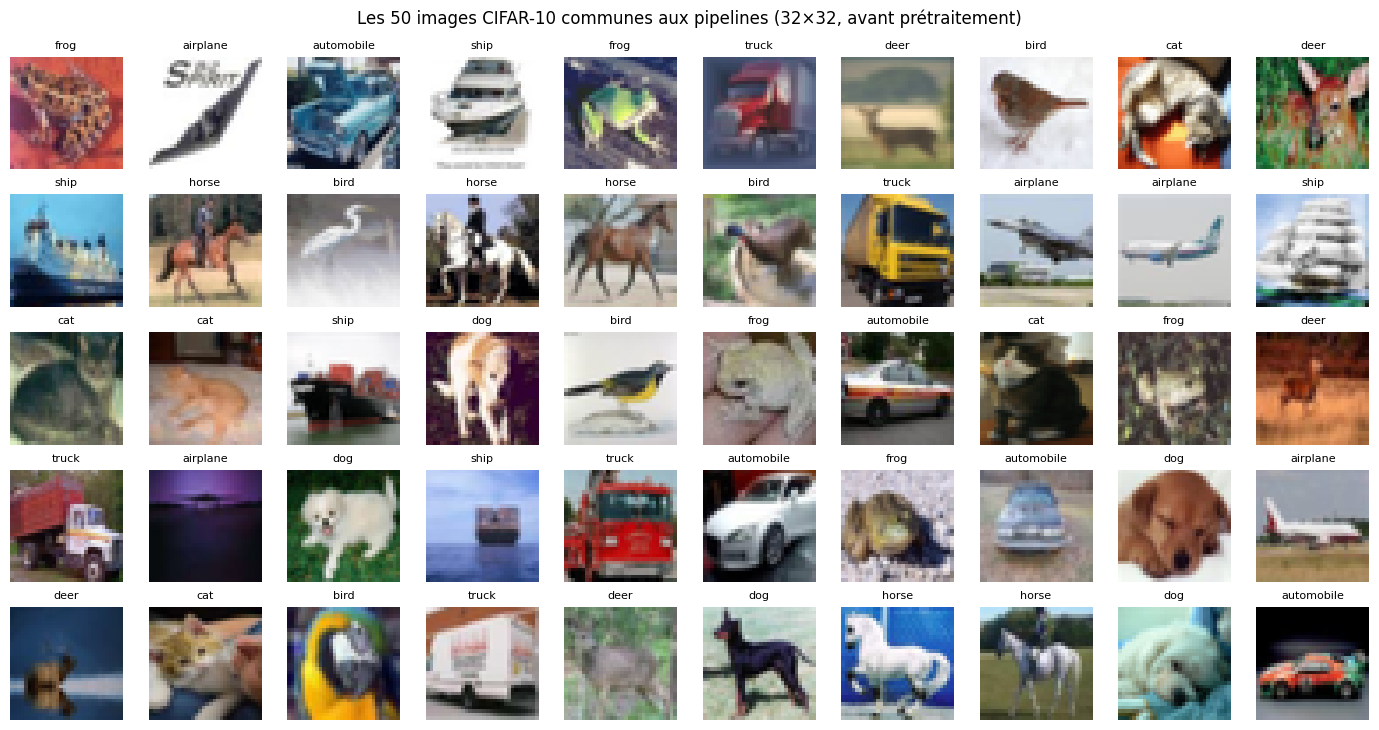

In [12]:
# ---------- 1.1 Sous-ensemble des 50 images (créé une seule fois, puis rechargé) ----------
if not os.path.exists(TEST50_PATH):
    labels_test = np.array(test_set.targets)
    rng = np.random.default_rng(SEED)
    idx = np.sort(np.concatenate([
        rng.choice(np.where(labels_test == c)[0], N_IMAGES // NUM_CLASSES, replace=False)
        for c in range(NUM_CLASSES)]))
    x50_uint8 = torch.from_numpy(test_set.data[idx])
    y50 = torch.from_numpy(labels_test[idx]).long()
    x50 = preprocess_uint8(x50_uint8).contiguous()
    torch.save({"images": x50, "labels": y50, "images_uint8": x50_uint8, "indices": idx.tolist(),
                "classes": CLASSES, "preprocessing": PREPROCESSING,
                "sha256": hashlib.sha256(x50.numpy().tobytes()).hexdigest()}, TEST50_PATH)
    print("Sous-ensemble créé :", TEST50_PATH)
else:
    print("Sous-ensemble existant rechargé :", TEST50_PATH)

T50 = torch.load(TEST50_PATH, weights_only=False)
X50, Y50 = T50["images"].contiguous(), T50["labels"]
Y50_NP = Y50.numpy()
X50_NP = np.ascontiguousarray(X50.numpy())
TEST_SHA = hashlib.sha256(X50.numpy().tobytes()).hexdigest()
assert TEST_SHA == T50["sha256"], "Empreinte des images incohérente"
assert T50["preprocessing"] == PREPROCESSING, "Paramètres de prétraitement différents"
print("Images :", tuple(X50.shape), X50.dtype, "| par classe :", np.bincount(Y50_NP))
print("Indices CIFAR-10 (test) :", T50["indices"])
print("SHA-256 des entrées :", TEST_SHA)

fig, axes = plt.subplots(5, 10, figsize=(14, 7.4))
for ax, img, lab in zip(axes.ravel(), T50["images_uint8"], Y50_NP):
    ax.imshow(img.numpy()); ax.set_title(CLASSES[lab], fontsize=8); ax.axis("off")
fig.suptitle("Les 50 images CIFAR-10 communes aux pipelines (32×32, avant prétraitement)")
plt.tight_layout(); plt.show()

In [13]:
# ---------- 1.2 Modèle 10 classes (créé une seule fois, puis rechargé) ----------
@torch.no_grad()
def extract_features(backbone, x_uint8, bs=100):
    out = []
    for i in range(0, len(x_uint8), bs):
        out.append(backbone(preprocess_uint8(torch.from_numpy(x_uint8[i:i + bs]))).flatten(1))
    return torch.cat(out)

if not os.path.exists(WEIGHTS_PATH):
    print("Création de la tête 10 classes par linear probing (réseau pré-entraîné gelé)…")
    torch.manual_seed(SEED)
    model = build_model(pretrained=True).eval()
    backbone = nn.Sequential(*list(model.children())[:-1]).eval()     # tout sauf fc -> [N,512,1,1]
    rng = np.random.default_rng(SEED)
    ytr_all, yte_all = np.array(train_set.targets), np.array(test_set.targets)
    tr_idx = np.sort(np.concatenate([rng.choice(np.where(ytr_all == c)[0], N_TRAIN_PER_CLASS, replace=False)
                                     for c in range(NUM_CLASSES)]))
    pool = np.setdiff1d(np.arange(len(yte_all)), np.array(T50["indices"]))   # jamais les 50 images
    va_idx = np.sort(rng.choice(pool, N_VAL, replace=False))
    t0 = time.time()
    f_tr = extract_features(backbone, train_set.data[tr_idx])
    f_va = extract_features(backbone, test_set.data[va_idx])
    print(f"Extraction des caractéristiques : {time.time() - t0:.0f} s")
    y_tr, y_va = torch.from_numpy(ytr_all[tr_idx]).long(), torch.from_numpy(yte_all[va_idx]).long()
    head = nn.Linear(512, NUM_CLASSES)
    opt = torch.optim.Adam(head.parameters(), lr=1e-2, weight_decay=1e-4)
    for it in range(500):
        opt.zero_grad()
        loss = F.cross_entropy(head(f_tr), y_tr)
        loss.backward(); opt.step()
    with torch.no_grad():
        acc_tr = (head(f_tr).argmax(1) == y_tr).float().mean().item() * 100
        acc_va = (head(f_va).argmax(1) == y_va).float().mean().item() * 100
    print(f"Tête 10 classes : perte {loss.item():.3f} | Top-1 entraînement {acc_tr:.1f} % | validation {acc_va:.1f} %")
    model.fc.load_state_dict(head.state_dict())
    torch.save(model.state_dict(), WEIGHTS_PATH)
    with open(MODEL_INFO_PATH, "w") as f:
        json.dump({"base": "torchvision resnet18 IMAGENET1K_V1 (gelé)", "head": "Linear(512,10)",
                   "method": "linear probing", "train_images": int(len(tr_idx)),
                   "val_images": int(len(va_idx)), "val_top1_pct": acc_va}, f, indent=2)
    del model, backbone, f_tr, f_va
else:
    print("Poids existants rechargés :", WEIGHTS_PATH)

model_ref = build_model(pretrained=False)
model_ref.load_state_dict(torch.load(WEIGHTS_PATH, map_location="cpu"))
model_ref.eval()
if os.path.exists(MODEL_INFO_PATH):
    with open(MODEL_INFO_PATH) as f:
        print("Modèle :", json.load(f))

Création de la tête 10 classes par linear probing (réseau pré-entraîné gelé)…
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 156MB/s]


Extraction des caractéristiques : 235 s
Tête 10 classes : perte 0.049 | Top-1 entraînement 99.9 % | validation 80.8 %
Modèle : {'base': 'torchvision resnet18 IMAGENET1K_V1 (gelé)', 'head': 'Linear(512,10)', 'method': 'linear probing', 'train_images': 3000, 'val_images': 500, 'val_top1_pct': 80.80000281333923}


In [14]:
# ---------- Spécifique GPU : entrées et modèle copiés une fois sur le GPU ----------
# Le transfert hôte → GPU n'est pas chronométré (comme le prétraitement côté CPU).
X50_GPU = X50.to(DEVICE).contiguous()
model_gpu = copy.deepcopy(model_ref).to(DEVICE).eval()
WEIGHTS_SHA = hashlib.sha256(open(WEIGHTS_PATH, "rb").read()).hexdigest()
# Enregistré avec chaque résultat : permet de vérifier, lors de la comparaison, que les 4 pipelines
# ont utilisé les mêmes images (indices) et le même modèle (empreinte des poids).
COMMON_EXTRA = {"test_indices": [int(i) for i in T50["indices"]], "weights_sha256": WEIGHTS_SHA}
print("Entrées sur", X50_GPU.device, "| SHA-256 (calculé sur les octets CPU, identique aux notebooks CPU) :", TEST_SHA[:16],
      "| poids :", WEIGHTS_SHA[:16])

Entrées sur cuda:0 | SHA-256 (calculé sur les octets CPU, identique aux notebooks CPU) : 117a8d622a1424cc | poids : 5af8ec3a559c95b0


## 2. Outils de mesure (identiques dans les deux notebooks)

**Protocole commun à tous les pipelines :**
* 50 images → **5 batches de 10**, entrées prétraitées une fois pour toutes (le prétraitement n'est pas chronométré) ;
* **5 passes de warm-up** non mesurées : allocations mémoire, compilation JIT / optimisation de graphe à la volée, remplissage des caches ;
* **10 passes mesurées** (≥ 3 exigées) chronométrées avec `time.perf_counter()` ;
* par passe : **temps d'inférence** des 50 images, **débit** = 50 / temps (images/s), **latence par batch** (moyenne, médiane, max), **précision Top-1**, accord avec la 1re passe ;
* pour chaque indicateur : **moyenne, écart-type, minimum, maximum, coefficient de variation** (CV = σ / moyenne) ;
* chaque exécution complète du notebook est enregistrée dans `results/history/` : relancer le notebook dans une nouvelle session ajoute une **exécution indépendante** (voir la dernière section).

**Énergie CPU** :
* **RAPL** (*Running Average Power Limit*, compteur d'énergie du package CPU dans `/sys/class/powercap`) est utilisé s'il est accessible → valeur **mesurée** ;
* sur les VM Colab, RAPL n'est en général **pas exposé** ; on calcule alors une **estimation** `E ≈ P_vCPU × temps CPU actif`, où le temps CPU actif (somme sur tous les vCPU) est lu par `psutil` et `P_vCPU = CPU_POWER_PER_VCPU_W` (hypothèse : un Xeon serveur ≈ 200 W pour 20–40 threads, soit ≈ 5–10 W par thread actif).
* La méthode utilisée est enregistrée avec chaque résultat. ⚠ Une estimation doit être présentée comme telle dans le rapport : elle est proportionnelle au temps CPU consommé, donc elle compare correctement les pipelines entre eux, mais sa valeur absolue dépend de l'hypothèse.

**Énergie GPU** (remplace la cellule « énergie CPU » des notebooks CPU, même interface `meter_factory`) :
* la bibliothèque **NVML** (celle de `nvidia-smi`) donne le **compteur d'énergie de la carte GPU** (mJ, disponible depuis l'architecture Volta : T4, L4, A100) → valeur **mesurée** ;
* si ce compteur n'existe pas, on échantillonne la puissance toutes les 50 ms et on l'intègre dans le temps ;
* la **puissance de repos** du GPU est mesurée au départ pour calculer l'énergie **nette** ;
* ⚠ seule la carte GPU est mesurée (ni le CPU hôte, ni la RAM) ; côté CPU l'énergie est en général **estimée** : le rapport doit le préciser lorsqu'il compare les deux plateformes.

In [15]:
# ============================================================
# Outils de mesure — IDENTIQUES dans les deux notebooks
# ============================================================
import os, time, json, datetime, glob
import numpy as np

def _to_py(o):
    # Conversion récursive numpy -> types Python (pour json.dump)
    if isinstance(o, dict):
        return {k: _to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_to_py(v) for v in o]
    if isinstance(o, np.generic):
        return o.item()
    if isinstance(o, np.ndarray):
        return o.tolist()
    return o

def describe(values):
    # Moyenne, écart-type (échantillon, ddof=1), min, max, coefficient de variation
    a = np.asarray(values, dtype=float)
    mean = float(a.mean())
    std = float(a.std(ddof=1)) if a.size > 1 else 0.0
    return {"mean": mean, "std": std, "min": float(a.min()), "max": float(a.max()),
            "cv_pct": (100.0 * std / mean) if mean else 0.0, "n": int(a.size)}

def to_numpy(out):
    if isinstance(out, np.ndarray):
        return out
    return out.detach().float().cpu().numpy()

def make_batches(images, batch_size):
    return [images[i:i + batch_size] for i in range(0, len(images), batch_size)]

def run_pass(infer_fn, batches, sync_fn, keep_outputs=True):
    # Une passe complète sur les 50 images. sync_fn() garantit que le calcul
    # est terminé avant d'arrêter le chronomètre (indispensable sur GPU : CUDA est asynchrone).
    outs, lat = [], []
    t0 = time.perf_counter()
    for xb in batches:
        ts = time.perf_counter()
        out = infer_fn(xb)
        sync_fn()
        lat.append(time.perf_counter() - ts)
        if keep_outputs:
            outs.append(out)
    return time.perf_counter() - t0, lat, outs

RUN_METRICS = ["total_time_ms", "throughput_img_s", "batch_latency_mean_ms",
               "batch_latency_p50_ms", "batch_latency_max_ms", "per_image_time_ms",
               "top1_acc_pct", "agreement_with_run0_pct"]
ENERGY_METRICS = ["energy_per_image_mj", "net_energy_per_image_mj", "mean_power_w",
                  "energy_j", "duration_s"]

def benchmark(infer_fn, images, labels_np, sync_fn, batch_size=None, n_warmup=None, n_runs=None):
    batch_size = batch_size or BATCH_SIZE
    n_warmup = N_WARMUP if n_warmup is None else n_warmup
    n_runs = n_runs or N_RUNS
    batches = make_batches(images, batch_size)
    n = sum(len(b) for b in batches)
    # 1) Warm-up : non mesuré (allocations, autotuning cuDNN, compilation JIT, montée en fréquence)
    for _ in range(n_warmup):
        run_pass(infer_fn, batches, sync_fn, keep_outputs=False)
    # 2) Répétitions mesurées
    runs, logits0 = [], None
    for r in range(n_runs):
        total, lat, outs = run_pass(infer_fn, batches, sync_fn)
        logits = np.concatenate([to_numpy(o) for o in outs]).astype(np.float32)
        preds = logits.argmax(1)
        if logits0 is None:
            logits0 = logits
        lat_ms = np.asarray(lat) * 1e3
        runs.append({
            "run": r,
            "total_time_ms": total * 1e3,
            "throughput_img_s": n / total,
            "batch_latency_mean_ms": float(lat_ms.mean()),
            "batch_latency_p50_ms": float(np.percentile(lat_ms, 50)),
            "batch_latency_max_ms": float(lat_ms.max()),
            "per_image_time_ms": total * 1e3 / n,
            "top1_acc_pct": float((preds == labels_np).mean() * 100),
            "agreement_with_run0_pct": float((preds == logits0.argmax(1)).mean() * 100),
        })
    return runs, logits0

def measure_energy(infer_fn, images, sync_fn, meter_factory, idle_power_w=0.0,
                   batch_size=None, min_seconds=None, n_reps=None):
    # Boucle de passes complètes pendant au moins `min_seconds` secondes,
    # pour que la mesure d'énergie couvre une durée exploitable.
    batch_size = batch_size or BATCH_SIZE
    min_seconds = min_seconds or ENERGY_MIN_SECONDS
    n_reps = n_reps or N_ENERGY_REPS
    batches = make_batches(images, batch_size)
    n = sum(len(b) for b in batches)
    reps = []
    for r in range(n_reps):
        n_img = 0
        with meter_factory() as m:
            t0 = time.perf_counter()
            while time.perf_counter() - t0 < min_seconds:
                run_pass(infer_fn, batches, sync_fn, keep_outputs=False)
                n_img += n
        e, dur = m.energy_j, m.duration_s
        reps.append({"rep": r, "method": m.method, "energy_j": e, "duration_s": dur,
                     "images": n_img, "mean_power_w": e / dur,
                     "energy_per_image_mj": 1e3 * e / n_img,
                     "net_energy_per_image_mj": 1e3 * max(e - idle_power_w * dur, 0.0) / n_img})
    return reps

def save_result(key, label, platform_name, family, precision, runs, logits,
                energy_reps=None, idle_power_w=None, extra=None):
    res = {
        "key": key, "label": label, "platform": platform_name, "family": family,
        "precision": precision, "batch_size": BATCH_SIZE, "n_images": int(len(logits)),
        "n_warmup": N_WARMUP, "n_runs": len(runs), "runs": runs,
        "summary": {m: describe([r[m] for r in runs]) for m in RUN_METRICS},
        "energy": None, "env": ENV, "test_sha256": TEST_SHA, "extra": extra or {},
        "session_id": globals().get("SESSION_ID"), "session_ref_key": globals().get("SESSION_REF_KEY"),
        "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    }
    if energy_reps:
        res["energy"] = {"method": energy_reps[0]["method"], "idle_power_w": idle_power_w,
                         "reps": energy_reps,
                         "summary": {m: describe([e[m] for e in energy_reps]) for m in ENERGY_METRICS}}
    np.save(f"{RESULTS}/{key}_logits.npy", logits)
    with open(f"{RESULTS}/{key}.json", "w") as f:
        json.dump(_to_py(res), f, indent=2, ensure_ascii=False)
    # historique : une copie par session, pour analyser la variabilité entre exécutions indépendantes
    os.makedirs(f"{RESULTS}/history", exist_ok=True)
    with open(f"{RESULTS}/history/{key}__{res['session_id']}.json", "w") as f:
        json.dump(_to_py(res), f, indent=2, ensure_ascii=False)
    s = res["summary"]
    msg = (f"[{label}] débit = {s['throughput_img_s']['mean']:.1f} ± {s['throughput_img_s']['std']:.1f} img/s"
           f" | latence/batch = {s['batch_latency_mean_ms']['mean']:.2f} ± {s['batch_latency_mean_ms']['std']:.2f} ms"
           f" | Top-1 = {s['top1_acc_pct']['mean']:.1f} %")
    if res["energy"]:
        msg += f" | énergie/image = {res['energy']['summary']['energy_per_image_mj']['mean']:.2f} mJ"
    print(msg)
    return res

def evaluate_pipeline(key, label, platform_name, family, precision, infer_fn, images, sync_fn,
                      meter_factory=None, idle_power_w=0.0, extra=None):
    runs, logits = benchmark(infer_fn, images, Y50_NP, sync_fn)
    reps = measure_energy(infer_fn, images, sync_fn, meter_factory, idle_power_w) if meter_factory else None
    return save_result(key, label, platform_name, family, precision, runs, logits,
                       energy_reps=reps, idle_power_w=idle_power_w, extra=extra)

print("Outils de mesure prêts.")

Outils de mesure prêts.


In [16]:
# ---------- Mesure d'énergie GPU (NVML) ----------
import threading
try:
    import pynvml
    pynvml.nvmlInit()
    NVML_HANDLE = pynvml.nvmlDeviceGetHandleByIndex(0)
except Exception as e:
    pynvml, NVML_HANDLE = None, None
    print("NVML indisponible :", e)

def _nvml_energy_mj():
    try:
        return pynvml.nvmlDeviceGetTotalEnergyConsumption(NVML_HANDLE)
    except Exception:
        return None

def _nvml_power_w():
    return pynvml.nvmlDeviceGetPowerUsage(NVML_HANDLE) / 1000.0

class GpuEnergyMeter:
    """Même interface que CpuEnergyMeter : attributs energy_j, duration_s, method."""
    interval_s = 0.05

    def _loop(self):
        while not self._stop.is_set():
            self._samples.append((time.perf_counter(), _nvml_power_w()))
            time.sleep(self.interval_s)

    def __enter__(self):
        torch.cuda.synchronize()
        self._samples, self._stop = [], threading.Event()
        self._e0 = _nvml_energy_mj()
        self._th = threading.Thread(target=self._loop, daemon=True)
        self._t0 = time.perf_counter()
        self._th.start()
        return self

    def __exit__(self, *exc):
        torch.cuda.synchronize()
        self.duration_s = time.perf_counter() - self._t0
        e1 = _nvml_energy_mj()
        self._stop.set(); self._th.join()
        if self._e0 is not None and e1 is not None and e1 > self._e0:
            self.energy_j = (e1 - self._e0) / 1000.0
            self.method = "NVML : compteur d'énergie de la carte GPU (mesuré)"
        else:
            ts = np.array([s[0] for s in self._samples]); ps = np.array([s[1] for s in self._samples])
            trapz = getattr(np, "trapezoid", None) or np.trapz
            self.energy_j = float(trapz(ps, ts)) if len(ts) > 1 else float("nan")
            self.method = "NVML : puissance échantillonnée × temps (mesuré)"
        self.peak_power_w = max((p for _, p in self._samples), default=float("nan"))
        return False

def measure_idle_power_gpu(seconds=5.0):
    torch.cuda.synchronize(); time.sleep(2.0)
    with GpuEnergyMeter() as m:
        time.sleep(seconds)
    return m.energy_j / m.duration_s

def cuda_sync():
    torch.cuda.synchronize()     # CUDA est asynchrone : on attend la fin réelle du calcul

GPU_METER = GpuEnergyMeter if NVML_HANDLE is not None else None
IDLE_W = measure_idle_power_gpu() if GPU_METER else 0.0
print(f"NVML accessible : {GPU_METER is not None} | puissance GPU au repos : {IDLE_W:.1f} W")

NVML accessible : True | puissance GPU au repos : 26.1 W


## 3. Référence : PyTorch eager FP32 sur GPU (dans cette session)
Le même modèle exécuté directement par PyTorch sur le GPU, opérateur par opérateur (chaque opération lance son propre kernel CUDA/cuDNN). Cette référence, mesurée **sur la même machine**, sert à calculer l'accélération apportée par TensorRT et à vérifier que ses prédictions sont identiques.

In [17]:
@torch.inference_mode()
def infer_eager_gpu(x):
    return model_gpu(x)

res_ref = evaluate_pipeline("gpu_trt_ref_eager", "Réf. eager FP32 (session TRT)", "GPU", "reference", "FP32",
                            infer_eager_gpu, X50_GPU, cuda_sync, GPU_METER, IDLE_W, extra=COMMON_EXTRA)

[Réf. eager FP32 (session TRT)] débit = 1020.4 ± 6.1 img/s | latence/batch = 9.80 ± 0.06 ms | Top-1 = 90.0 % | énergie/image = 69.01 mJ


## 4. Pipeline GPU n°1 : PyTorch → ONNX → TensorRT → CUDA/cuDNN → GPU

### 4.1 Format du modèle : ONNX
On réutilise **le même fichier ONNX que le pipeline CPU n°1** (`opset 17`, axe batch dynamique, *constant folding*) : seul le *middle level* change entre OpenVINO (CPU) et TensorRT (GPU). S'il n'existe pas encore, il est créé ici avec exactement les mêmes paramètres.

In [18]:
import onnx
from collections import Counter

def export_onnx(model, path, dummy):
    """Même export que le notebook CPU n°1 ; si l'exporteur historique n'existe plus, exporteur dynamo."""
    kw = dict(input_names=["input"], output_names=["logits"], opset_version=17)
    try:
        torch.onnx.export(model, dummy, path, dynamo=False, do_constant_folding=True,
                          dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}}, **kw)
        return "torch.onnx (TorchScript)"
    except TypeError:
        torch.onnx.export(model, dummy, path, do_constant_folding=True,
                          dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}}, **kw)
        return "torch.onnx (TorchScript)"
    except Exception as e:
        print(f"Exporteur historique indisponible ({type(e).__name__}) → exporteur dynamo")
        batch = torch.export.Dim("batch", min=1, max=256)
        torch.onnx.export(model, (dummy,), path, dynamo=True, dynamic_shapes={"x": {0: batch}}, **kw)
        return "torch.onnx (dynamo)"

if not os.path.exists(ONNX_PATH):
    t0 = time.perf_counter()
    exporter = export_onnx(model_ref, ONNX_PATH, torch.randn(BATCH_SIZE, 3, IMG_SIZE, IMG_SIZE))
    print(f"Export ONNX ({exporter}) : {time.perf_counter() - t0:.1f} s")
else:
    print("Fichier ONNX existant (créé par un autre notebook) rechargé :", ONNX_PATH)
onnx_model = onnx.load(ONNX_PATH)
onnx.checker.check_model(onnx_model)
N_ONNX_NODES = len(onnx_model.graph.node)
ONNX_OPS = Counter(n.op_type for n in onnx_model.graph.node)
ONNX_SHA = hashlib.sha256(open(ONNX_PATH, "rb").read()).hexdigest()
print(f"{ONNX_PATH} — {os.path.getsize(ONNX_PATH) / 1e6:.1f} Mo — {N_ONNX_NODES} nœuds — SHA-256 {ONNX_SHA[:16]}")
print("Opérateurs ONNX :", dict(ONNX_OPS))

/tmp/ipykernel_538/2395344665.py:8: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, dummy, path, dynamo=False, do_constant_folding=True,


Export ONNX (torch.onnx (TorchScript)) : 1.1 s
/content/drive/MyDrive/TP_Deploiement_IA/shared/resnet18_cifar10.onnx — 44.7 Mo — 49 nœuds — SHA-256 21c918039f575c84
Opérateurs ONNX : {'Conv': 20, 'Relu': 17, 'MaxPool': 1, 'Add': 8, 'GlobalAveragePool': 1, 'Flatten': 1, 'Gemm': 1}


### 4.2 Middle level : construction des moteurs TensorRT
* `OnnxParser` convertit le graphe ONNX en réseau TensorRT ;
* le *builder* applique les optimisations : **fusion** Conv + (BatchNorm repliée) + ReLU + addition résiduelle, élimination des copies, choix de la disposition mémoire, et **sélection par chronométrage** (*tactics*) du kernel le plus rapide pour chaque couche **sur ce GPU précis** (cuDNN, cuBLAS ou kernels propres à TensorRT) ;
* la forme d'entrée est fixée au batch commun (`BATCH_SIZE` = 10) : les kernels sont choisis pour exactement cette forme ;
* **FP16** : TensorRT est autorisé à exécuter les couches en demi-précision sur les **Tensor Cores** du T4 (les entrées/sorties restent en FP32) ;
* le moteur sérialisé (`.engine`) est **spécifique** au modèle de GPU et à la version de TensorRT : il n'est pas partagé sur le Drive.

In [19]:
ONNX_FOR = {"FP32": ONNX_PATH, "FP16": ONNX_PATH}
if TRT_OK:
    TRT_LOGGER = trt.Logger(trt.Logger.WARNING)
    TRT_MAJOR = int(trt.__version__.split(".")[0])
    HAS_FP16_FLAG = hasattr(trt.BuilderFlag, "FP16")
    TRT2TORCH = {trt.DataType.FLOAT: torch.float32, trt.DataType.HALF: torch.float16}
    if RUN_FP16 and not HAS_FP16_FLAG:
        # Versions récentes de TensorRT : le FP16 passe par un réseau « strongly typed » construit depuis un ONNX en FP16
        try:
            ONNX_FOR["FP16"] = f"{WORK}/resnet18_cifar10_fp16.onnx"
            m16 = copy.deepcopy(model_ref).to(DEVICE).half().eval()
            export_onnx(m16, ONNX_FOR["FP16"], torch.randn(BATCH_SIZE, 3, IMG_SIZE, IMG_SIZE, device=DEVICE).half())
            del m16
        except Exception as e:
            FAILED["TensorRT FP16 (export ONNX FP16)"] = repr(e)
            print("⚠ Export ONNX FP16 impossible, variante FP16 ignorée :", repr(e))
            RUN_FP16 = False

def build_engine(onnx_path, batch_size, precision):
    builder = trt.Builder(TRT_LOGGER)
    flags = 0
    if TRT_MAJOR < 10:
        flags |= 1 << int(trt.NetworkDefinitionCreationFlag.EXPLICIT_BATCH)
    if precision == "FP16" and not HAS_FP16_FLAG:
        flags |= 1 << int(trt.NetworkDefinitionCreationFlag.STRONGLY_TYPED)
    network = builder.create_network(flags)
    parser = trt.OnnxParser(network, TRT_LOGGER)
    if not parser.parse_from_file(onnx_path):
        raise RuntimeError("\n".join(str(parser.get_error(i)) for i in range(parser.num_errors)))
    config = builder.create_builder_config()
    config.set_memory_pool_limit(trt.MemoryPoolType.WORKSPACE, 2 << 30)      # 2 Go d'espace de travail
    try:
        config.profiling_verbosity = trt.ProfilingVerbosity.DETAILED          # pour inspecter les couches fusionnées
    except Exception:
        pass
    if precision == "FP16" and HAS_FP16_FLAG:
        config.set_flag(trt.BuilderFlag.FP16)
    shape = (batch_size, 3, IMG_SIZE, IMG_SIZE)
    profile = builder.create_optimization_profile()
    profile.set_shape(network.get_input(0).name, shape, shape, shape)
    config.add_optimization_profile(profile)
    t0 = time.perf_counter()
    plan = builder.build_serialized_network(network, config)
    if plan is None:
        raise RuntimeError("Échec de la construction du moteur TensorRT")
    return bytes(plan), time.perf_counter() - t0


class TRTRunner:
    """Exécute un moteur TensorRT sur des tenseurs PyTorch déjà présents sur le GPU (aucune copie hôte)."""

    def __init__(self, plan):
        self.runtime = trt.Runtime(TRT_LOGGER)
        self.engine = self.runtime.deserialize_cuda_engine(plan)
        self.context = self.engine.create_execution_context()
        names = [self.engine.get_tensor_name(i) for i in range(self.engine.num_io_tensors)]
        self.inp = next(n for n in names if self.engine.get_tensor_mode(n) == trt.TensorIOMode.INPUT)
        self.out = next(n for n in names if self.engine.get_tensor_mode(n) == trt.TensorIOMode.OUTPUT)
        self.in_dtype = TRT2TORCH[self.engine.get_tensor_dtype(self.inp)]
        self.out_dtype = TRT2TORCH[self.engine.get_tensor_dtype(self.out)]
        self.stream = torch.cuda.Stream()      # flux CUDA dédié (évite les synchronisations implicites du flux par défaut)
        self.shape = None

    def __call__(self, x):
        x = x.to(self.in_dtype).contiguous()
        if tuple(x.shape) != self.shape:
            self.shape = tuple(x.shape)
            self.context.set_input_shape(self.inp, self.shape)
            self.out_shape = tuple(self.context.get_tensor_shape(self.out))
        out = torch.empty(self.out_shape, dtype=self.out_dtype, device=DEVICE)   # nouvelle sortie à chaque appel
        self.context.set_tensor_address(self.inp, x.data_ptr())
        self.context.set_tensor_address(self.out, out.data_ptr())
        cur = torch.cuda.current_stream()
        self.stream.wait_stream(cur)
        self.context.execute_async_v3(self.stream.cuda_stream)
        cur.wait_stream(self.stream)
        return out


ENGINES = {}
for prec in ((["FP32", "FP16"] if RUN_FP16 else ["FP32"]) if TRT_OK else []):
    try:
        plan, build_s = build_engine(ONNX_FOR[prec], BATCH_SIZE, prec)
        with open(f"{WORK}/resnet18_{prec.lower()}_bs{BATCH_SIZE}.engine", "wb") as f:
            f.write(plan)
        ENGINES[prec] = {"plan": plan, "build_s": build_s, "runner": TRTRunner(plan)}
        print(f"Moteur {prec} : construit en {build_s:.1f} s | {len(plan) / 1e6:.1f} Mo")
    except Exception as e:
        FAILED[f"TensorRT {prec} (construction du moteur)"] = repr(e)
        print(f"⚠ Moteur TensorRT {prec} impossible à construire, variante ignorée :", repr(e))
if TRT_OK:
    print("TensorRT", trt.__version__, "| mode FP16 :", "BuilderFlag.FP16" if HAS_FP16_FLAG else "réseau strongly typed")

/tmp/ipykernel_538/2395344665.py:8: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, dummy, path, dynamo=False, do_constant_folding=True,


Moteur FP32 : construit en 7.4 s | 52.2 Mo
Moteur FP16 : construit en 11.3 s | 22.6 Mo
TensorRT 11.5.0.63 | mode FP16 : réseau strongly typed


### 4.3 Ce que TensorRT a fait du graphe : fusion d'opérateurs et sélection des kernels
L'*inspecteur de moteur* décrit le graphe réellement exécuté : nombre de couches après fusion (à comparer au nombre de nœuds ONNX) et, pour chaque couche, le kernel (*tactic*) retenu.

In [20]:
import pandas as pd

def engine_layers(engine):
    try:
        insp = engine.create_engine_inspector()
        info = json.loads(insp.get_engine_information(trt.LayerInformationFormat.JSON))
    except Exception as e:
        print("Inspection indisponible :", e)
        return pd.DataFrame()
    rows = []
    for l in info.get("Layers", []):
        if isinstance(l, dict):
            rows.append({"couche": l.get("Name", "")[:110], "type": l.get("LayerType", ""),
                         "kernel (tactic)": str(l.get("TacticName", l.get("TacticValue", "")))[:70],
                         "précision": str((l.get("Outputs") or [{}])[0].get("Format/Datatype", ""))[:30]})
        else:
            rows.append({"couche": str(l)[:110], "type": "", "kernel (tactic)": "", "précision": ""})
    return pd.DataFrame(rows)

TRT_LAYERS = {p: engine_layers(e["runner"].engine) for p, e in ENGINES.items()}
for p, df in TRT_LAYERS.items():
    print(f"[{p}] nœuds ONNX : {N_ONNX_NODES}  →  couches exécutées par TensorRT : {len(df)}")
    if len(df) and "type" in df and df["type"].astype(bool).any():
        print("     couches par type :", dict(Counter(df["type"])))
if TRT_LAYERS:
    display(next(iter(TRT_LAYERS.values())).head(15))

[FP32] nœuds ONNX : 49  →  couches exécutées par TensorRT : 25
     couches par type : {'CaskConvolution': 20, 'CaskPooling': 2, 'Reformat': 1, 'NoOp': 1, 'gemm': 1}
[FP16] nœuds ONNX : 49  →  couches exécutées par TensorRT : 25
     couches par type : {'Reformat': 1, 'CaskConvolution': 20, 'CaskPooling': 2, 'NoOp': 1, 'gemm': 1}


,couche,type,kernel (tactic),précision
0,/conv1/Conv + /relu/Relu,CaskConvolution,volta_scudnn_128x64_relu_xregs_large_nn_v1,
1,/maxpool/MaxPool,CaskPooling,sm50_xmma_pooling_nd_NCDHW_kMAX_kGENERIC_3D_PO...,
2,/layer1/layer1.0/conv1/Conv + /layer1/layer1.0...,CaskConvolution,volta_scudnn_winograd_128x128_ldg1_ldg4_relu_t...,
3,/layer1/layer1.0/conv2/Conv + /layer1/layer1.0...,CaskConvolution,volta_scudnn_winograd_128x128_ldg1_ldg4_relu_t...,
4,/layer1/layer1.1/conv1/Conv + /layer1/layer1.1...,CaskConvolution,volta_scudnn_winograd_128x128_ldg1_ldg4_relu_t...,
5,/layer1/layer1.1/conv2/Conv + /layer1/layer1.1...,CaskConvolution,volta_scudnn_winograd_128x128_ldg1_ldg4_relu_t...,
6,/layer2/layer2.0/conv1/Conv + /layer2/layer2.0...,CaskConvolution,volta_scudnn_128x128_relu_small_nn_v1,
7,/layer2/layer2.0/conv2/Conv,CaskConvolution,volta_scudnn_winograd_128x128_ldg1_ldg4_relu_t...,
8,/layer2/layer2.0/downsample/downsample.0/Conv ...,CaskConvolution,volta_scudnn_128x128_relu_interior_nn_v1,
9,/layer2/layer2.1/conv1/Conv + /layer2/layer2.1...,CaskConvolution,volta_scudnn_winograd_128x128_ldg1_ldg4_relu_t...,


### 4.4 Contrôle numérique puis mesures (TensorRT FP32 et FP16)
On vérifie d'abord que les sorties de TensorRT coïncident avec celles de PyTorch (mêmes batches de 10), puis on applique **exactement le même protocole** que pour la référence.

In [21]:
with torch.inference_mode():
    ref_logits = np.concatenate([to_numpy(model_gpu(X50_GPU[i:i + BATCH_SIZE])) for i in range(0, N_IMAGES, BATCH_SIZE)])

TRT_RESULTS = {}
for prec, eng in list(ENGINES.items()):
    try:
        runner = eng["runner"]
        logits = np.concatenate([to_numpy(runner(X50_GPU[i:i + BATCH_SIZE])) for i in range(0, N_IMAGES, BATCH_SIZE)])
        print(f"[{prec}] max |logit PyTorch − logit TensorRT| = {np.abs(ref_logits - logits).max():.2e} | "
              f"accord Top-1 = {100 * (ref_logits.argmax(1) == logits.argmax(1)).mean():.0f} %")
        TRT_RESULTS[prec] = evaluate_pipeline(
            f"gpu1_trt_{prec.lower()}", f"GPU-1 TensorRT {prec}", "GPU", "pipeline1", prec,
            runner, X50_GPU, cuda_sync, GPU_METER, IDLE_W,
            extra={**COMMON_EXTRA, "engine_build_s": eng["build_s"], "engine_size_mb": len(eng["plan"]) / 1e6,
                   "onnx_nodes": N_ONNX_NODES, "trt_layers": int(len(TRT_LAYERS.get(prec, []))),
                   "tensorrt": trt.__version__, "onnx_sha256": ONNX_SHA})
    except Exception as e:
        FAILED[f"TensorRT {prec} (mesures)"] = repr(e)
        ENGINES.pop(prec, None)
        print(f"⚠ Mesures TensorRT {prec} impossibles, variante ignorée :", repr(e))

[FP32] max |logit PyTorch − logit TensorRT| = 7.25e-05 | accord Top-1 = 100 %
[GPU-1 TensorRT FP32] débit = 1235.4 ± 15.5 img/s | latence/batch = 8.09 ± 0.10 ms | Top-1 = 90.0 % | énergie/image = 55.80 mJ
[FP16] max |logit PyTorch − logit TensorRT| = 1.01e-01 | accord Top-1 = 100 %
[GPU-1 TensorRT FP16] débit = 4272.2 ± 111.2 img/s | latence/batch = 2.34 ± 0.06 ms | Top-1 = 90.0 % | énergie/image = 15.88 mJ


### 4.5 Bas niveau : quels kernels CUDA sont réellement exécutés ?
`torch.profiler` (CUPTI) enregistre chaque kernel lancé sur le GPU pendant 3 batches. On compare :
* **eager** : un kernel par opération (convolutions cuDNN, BatchNorm, ReLU, additions…) ;
* **TensorRT** : moins de kernels (couches fusionnées), choisis parmi cuDNN/cuBLAS et les kernels propres à TensorRT ; en FP16 les noms font apparaître les Tensor Cores (`h884`, `h1688`, `fp16`…).

,kernels distincts,lancements de kernels / batch,temps GPU profilé (ms/batch)
Réf. eager FP32,20.0,106.0,9.02
TensorRT FP32,12.0,24.0,6.23
TensorRT FP16,16.0,25.0,1.87


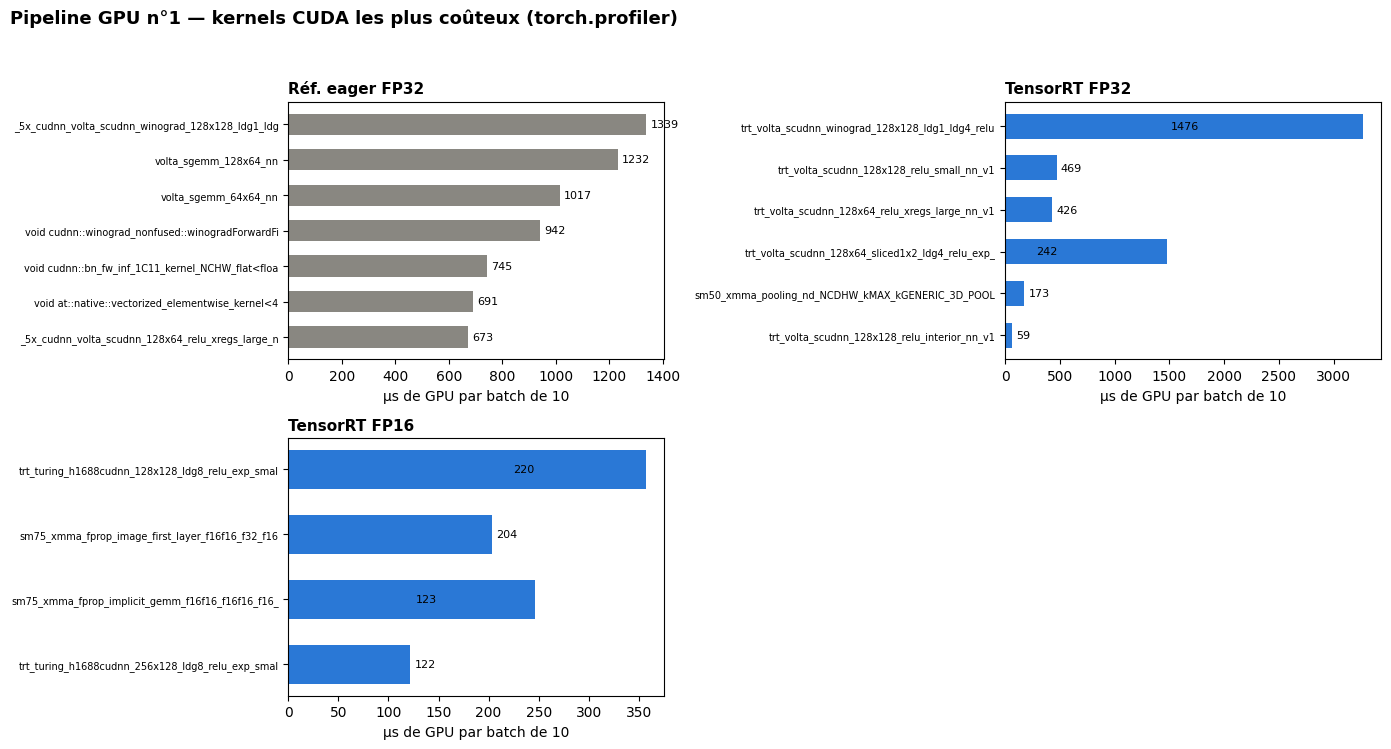


=== Réf. eager FP32 ===


,kernel,appels/batch,temps GPU (µs/batch)
5,_5x_cudnn_volta_scudnn_winograd_128x128_ldg1_l...,4.0,1338.9
18,volta_sgemm_128x64_nn,6.0,1231.5
19,volta_sgemm_64x64_nn,3.0,1016.8
15,void cudnn::winograd_nonfused::winogradForward...,9.0,941.7
12,void cudnn::bn_fw_inf_1C11_kernel_NCHW_flat<fl...,15.0,744.6
8,void at::native::vectorized_elementwise_kernel...,17.0,691.2
4,_5x_cudnn_volta_scudnn_128x64_relu_xregs_large...,2.0,673.0
14,void cudnn::winograd_nonfused::winogradForward...,9.0,523.8



=== TensorRT FP32 ===


,kernel,appels/batch,temps GPU (µs/batch)
10,trt_volta_scudnn_winograd_128x128_ldg1_ldg4_re...,10.0,3268.7
9,trt_volta_scudnn_128x64_sliced1x2_ldg4_relu_ex...,3.0,1475.6
4,trt_volta_scudnn_128x128_relu_small_nn_v1,2.0,469.0
6,trt_volta_scudnn_128x64_relu_xregs_large_nn_v1,1.0,426.4
8,trt_volta_scudnn_128x64_sliced1x2_ldg4_relu_ex...,1.0,242.5
1,sm50_xmma_pooling_nd_NCDHW_kMAX_kGENERIC_3D_PO...,1.0,173.1
3,trt_volta_scudnn_128x128_relu_interior_nn_v1,1.0,59.5
5,trt_volta_scudnn_128x64_relu_interior_nn_v1,1.0,42.8



=== TensorRT FP16 ===


,kernel,appels/batch,temps GPU (µs/batch)
11,trt_turing_h1688cudnn_128x128_ldg8_relu_exp_sm...,5.0,357.4
9,sm75_xmma_fprop_implicit_gemm_f16f16_f16f16_f1...,2.0,246.3
4,sm75_xmma_fprop_implicit_gemm_f16f16_f16f16_f1...,2.0,234.1
5,sm75_xmma_fprop_implicit_gemm_f16f16_f16f16_f1...,2.0,220.1
3,sm75_xmma_fprop_image_first_layer_f16f16_f32_f...,1.0,203.7
8,sm75_xmma_fprop_implicit_gemm_f16f16_f16f16_f1...,1.0,123.4
13,trt_turing_h1688cudnn_256x128_ldg8_relu_exp_sm...,2.0,121.8
1,sm50_xmma_pooling_max_nhwc_FP16FP32_WINDOWSIZE...,1.0,91.7


In [22]:
# ---------- Profilage GPU : quels kernels CUDA sont réellement exécutés ? ----------
from torch.profiler import profile, ProfilerActivity

def _dev_time_us(e):
    for attr in ("device_time_total", "cuda_time_total", "device_time", "cuda_time"):
        v = getattr(e, attr, None)
        if v:
            return float(v)
    return 0.0

PROFILE_COLUMNS = ["kernel", "appels/batch", "temps GPU (µs/batch)"]

def profile_gpu_kernels(fn, n=3):
    try:
        return _profile_gpu_kernels(fn, n)
    except Exception as e:
        print("Profilage impossible pour cette variante :", repr(e)[:200])
        return pd.DataFrame(columns=PROFILE_COLUMNS)

def _profile_gpu_kernels(fn, n):
    with torch.inference_mode():
        fn(X50_GPU[:BATCH_SIZE]); torch.cuda.synchronize()
        with profile(activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA]) as prof:
            for i in range(n):
                fn(X50_GPU[i * BATCH_SIZE:(i + 1) * BATCH_SIZE])
            torch.cuda.synchronize()
    evts = [e for e in prof.events() if e.device_type == torch.autograd.DeviceType.CUDA]
    df = pd.DataFrame([{"kernel": e.name, "t": _dev_time_us(e)} for e in evts])
    if df.empty:
        return pd.DataFrame(columns=PROFILE_COLUMNS)
    df = df.groupby("kernel")["t"].agg(["count", "sum"]).reset_index()
    df["appels/batch"] = df["count"] / n
    df["temps GPU (µs/batch)"] = df["sum"] / n
    return df[["kernel", "appels/batch", "temps GPU (µs/batch)"]].sort_values("temps GPU (µs/batch)", ascending=False)

def gpu_profile_report(profiles, suptitle, fname, colors):
    profiles = {k: v for k, v in profiles.items() if len(v)}
    if not profiles:
        print("Aucun profil disponible.")
        return pd.DataFrame()
    summary = pd.DataFrame({k: {"kernels distincts": len(v), "lancements de kernels / batch": v["appels/batch"].sum(),
                                "temps GPU profilé (ms/batch)": v["temps GPU (µs/batch)"].sum() / 1e3}
                            for k, v in profiles.items() if len(v)}).T
    display(summary.round(2))
    fig, axes = plt.subplots(int(np.ceil(len(profiles) / 2)), 2, figsize=(14, 3.8 * int(np.ceil(len(profiles) / 2))))
    for ax, (name, df) in zip(np.atleast_1d(axes).ravel(), profiles.items()):
        top = df.head(7)[::-1]
        ax.barh([o[:48] for o in top["kernel"]], top["temps GPU (µs/batch)"], color=colors.get(name, "#898781"), height=0.6)
        for i, v in enumerate(top["temps GPU (µs/batch)"]):
            ax.annotate(f"{v:.0f}", (v, i), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)
        ax.set_title(name, loc="left", fontsize=11, fontweight="bold")
        ax.set_xlabel(f"µs de GPU par batch de {BATCH_SIZE}")
        ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=7)
    for ax in np.atleast_1d(axes).ravel()[len(profiles):]:
        ax.axis("off")
    fig.suptitle(suptitle, fontsize=13, fontweight="bold", x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0, 1, 0.95)); fig.savefig(f"{FIGS}/{fname}", bbox_inches="tight"); plt.show()
    for name, df in profiles.items():
        print(f"\n=== {name} ==="); display(df.head(8).round(1))
    return summary

PROFILES = {"Réf. eager FP32": profile_gpu_kernels(infer_eager_gpu)}
for prec, eng in ENGINES.items():
    PROFILES[f"TensorRT {prec}"] = profile_gpu_kernels(eng["runner"])
prof_summary = gpu_profile_report(PROFILES, "Pipeline GPU n°1 — kernels CUDA les plus coûteux (torch.profiler)",
                                  "trt_profil_kernels.png",
                                  {"Réf. eager FP32": "#898781", "TensorRT FP32": "#2a78d6", "TensorRT FP16": "#2a78d6"})

### 4.6 (Optionnel) Effet de la taille de batch sur GPU
Hors protocole commun : un GPU n'est pleinement exploité qu'avec assez d'images en parallèle. On reconstruit des moteurs pour les batches 1 et 50 et on mesure débit et latence (5 répétitions). Ces résultats sont enregistrés à part (`results/batch_study/`) et **n'entrent pas** dans la comparaison des 4 pipelines. Mettre `RUN_BATCH_STUDY = False` pour passer cette étape.

Réf. eager FP32              batch  1 :    279.7 ±  11.4 img/s | latence/batch 3.58 ms
Réf. eager FP32              batch 10 :    892.8 ±   2.8 img/s | latence/batch 11.20 ms
Réf. eager FP32              batch 50 :   1079.7 ±   8.9 img/s | latence/batch 46.31 ms
TensorRT FP32                batch  1 :    663.2 ±  11.0 img/s | latence/batch 1.51 ms
TensorRT FP32                batch 10 :   1129.2 ±   9.4 img/s | latence/batch 8.85 ms
TensorRT FP32                batch 50 :   1157.2 ±  10.8 img/s | latence/batch 43.21 ms
TensorRT FP16                batch  1 :   1494.6 ±  38.4 img/s | latence/batch 0.67 ms
TensorRT FP16                batch 10 :   4053.6 ±  62.6 img/s | latence/batch 2.47 ms
TensorRT FP16                batch 50 :   5294.1 ±  76.4 img/s | latence/batch 9.44 ms


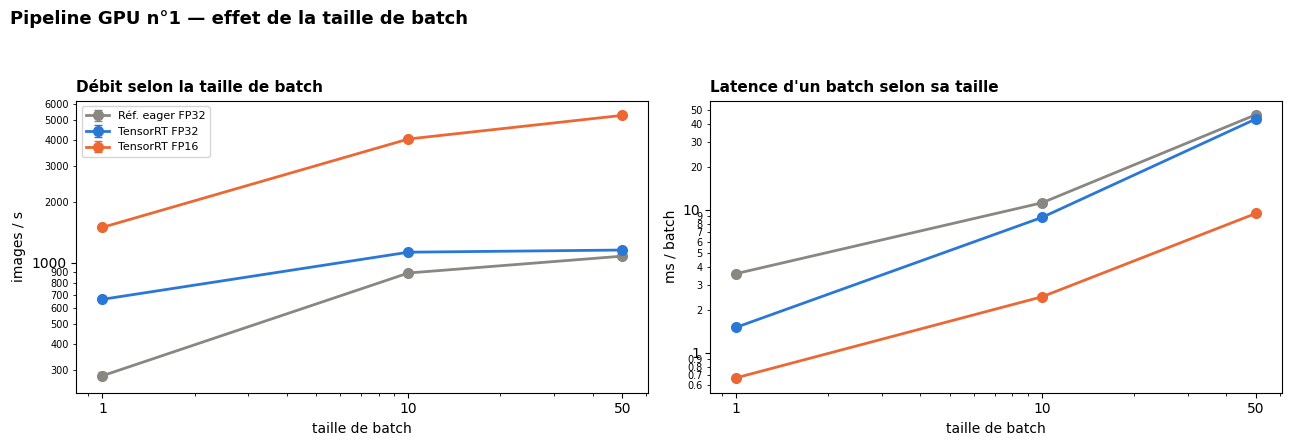

,variante,batch,débit (img/s),débit σ,latence batch (ms),latence σ,Top-1 %
0,Réf. eager FP32,1,279.74,11.40,3.58,0.15,90.0
1,Réf. eager FP32,10,892.84,2.80,11.20,0.04,90.0
2,Réf. eager FP32,50,1079.75,8.92,46.31,0.39,90.0
3,TensorRT FP32,1,663.21,11.05,1.51,0.03,90.0
4,TensorRT FP32,10,1129.24,9.38,8.85,0.07,90.0
5,TensorRT FP32,50,1157.17,10.81,43.21,0.40,90.0
6,TensorRT FP16,1,1494.55,38.35,0.67,0.02,90.0
7,TensorRT FP16,10,4053.62,62.62,2.47,0.04,90.0
8,TensorRT FP16,50,5294.08,76.42,9.44,0.14,90.0


In [23]:
# ---------- Étude complémentaire : effet de la taille de batch sur GPU ----------
# Hors protocole commun (batch 10) : ces mesures ne sont PAS enregistrées dans results/*.json
# (la comparaison des 4 pipelines exige le même batch). Elles sont sauvegardées à part.
import matplotlib.ticker

def batch_study(variants, batch_sizes, fname, title):
    rows = []
    for label, make_fn in variants:
        for b in batch_sizes:
            fn = make_fn(b)
            runs, _ = benchmark(fn, X50_GPU, Y50_NP, cuda_sync, batch_size=b, n_runs=5)
            tp = describe([r["throughput_img_s"] for r in runs])
            lat = describe([r["batch_latency_mean_ms"] for r in runs])
            rows.append({"variante": label, "batch": b, "débit (img/s)": tp["mean"], "débit σ": tp["std"],
                         "latence batch (ms)": lat["mean"], "latence σ": lat["std"],
                         "Top-1 %": runs[0]["top1_acc_pct"]})
            print(f"{label:<28} batch {b:>2} : {tp['mean']:8.1f} ± {tp['std']:5.1f} img/s | latence/batch {lat['mean']:.2f} ms")
    df = pd.DataFrame(rows)
    os.makedirs(f"{RESULTS}/batch_study", exist_ok=True)
    df.to_csv(f"{RESULTS}/batch_study/{fname}.csv", index=False)
    pal = ["#898781", "#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for i, (lab, g) in enumerate(df.groupby("variante", sort=False)):
        axes[0].errorbar(g["batch"], g["débit (img/s)"], yerr=g["débit σ"], marker="o", lw=2, ms=7, capsize=3, color=pal[i % 5], label=lab)
        axes[1].errorbar(g["batch"], g["latence batch (ms)"], yerr=g["latence σ"], marker="o", lw=2, ms=7, capsize=3, color=pal[i % 5], label=lab)
    for ax, yl, t in [(axes[0], "images / s", "Débit selon la taille de batch"),
                      (axes[1], "ms / batch", "Latence d'un batch selon sa taille")]:
        ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xticks(batch_sizes); ax.set_xticklabels(batch_sizes)
        ax.set_xlabel("taille de batch"); ax.set_ylabel(yl); ax.set_title(t, loc="left", fontsize=11, fontweight="bold")
        fmt = matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}")
        ax.yaxis.set_major_formatter(fmt); ax.yaxis.set_minor_formatter(fmt); ax.tick_params(axis="y", which="minor", labelsize=7)
    axes[0].legend(fontsize=8)
    fig.suptitle(title, fontsize=13, fontweight="bold", x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0, 1, 0.93)); fig.savefig(f"{FIGS}/{fname}.png", bbox_inches="tight"); plt.show()
    return df

if RUN_BATCH_STUDY:
    try:
        STUDY_BS = [1, 10, 50]
        STUDY_RUNNERS = {(p, BATCH_SIZE): e["runner"] for p, e in ENGINES.items()}
        for p in ENGINES:
            for b in STUDY_BS:
                if (p, b) not in STUDY_RUNNERS:
                    plan, _ = build_engine(ONNX_FOR[p], b, p)
                    STUDY_RUNNERS[(p, b)] = TRTRunner(plan)
        variants = [("Réf. eager FP32", lambda b: infer_eager_gpu)]
        variants += [(f"TensorRT {p}", (lambda p: lambda b: STUDY_RUNNERS[(p, b)])(p)) for p in ENGINES]
        df_bs = batch_study(variants, STUDY_BS, "trt_taille_batch", "Pipeline GPU n°1 — effet de la taille de batch")
        display(df_bs.round(2))
    except Exception as e:
        FAILED["Étude des tailles de batch"] = repr(e)
        print("⚠ Étude des tailles de batch interrompue (sans effet sur les autres résultats) :", repr(e))

## 5. Résultats du pipeline GPU n°1 (TensorRT) (vs référence de la même session)
Barres d'erreur : **± 1 écart-type** sur les 10 répétitions (3 pour l'énergie). Les fonctions de graphiques sont celles des notebooks CPU (cellule identique).

In [24]:
# ============================================================
# Outils de visualisation et de comparaison — IDENTIQUES dans les deux notebooks
# ============================================================
import os, glob, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
# Une couleur par famille de pipeline (même couleur dans tous les graphiques) ;
# les variantes FP16 sont hachurées pour ne pas reposer sur la couleur seule.
FAMILY_COLORS = {"reference": "#898781", "pipeline1": "#2a78d6", "pipeline2": "#eb6834"}
FAMILY_NAMES = {"reference": "Référence : PyTorch eager",
                "pipeline1": "Pipeline n°1 : ONNX → moteur spécialisé (OpenVINO / TensorRT)",
                "pipeline2": "Pipeline n°2 : compilation PyTorch (TorchScript / torch.compile)"}
HATCHES = {"FP16": "///", "INT8": "xx"}

def load_results(keys=None):
    allres = {}
    for p in sorted(glob.glob(f"{RESULTS}/*.json")):
        with open(p) as f:
            r = json.load(f)
        if "key" in r and "summary" in r:
            allres[r["key"]] = r
    if keys is None:
        return allres
    return {k: allres[k] for k in keys if k in allres}

def _stat(r, name, energy=False):
    if energy:
        if not r.get("energy"):
            return None
        return r["energy"]["summary"].get(name)
    return r["summary"].get(name)

def bar_chart(ax, results, name, ylabel, title, energy=False, log=False, fmt="{:.1f}", baseline=None):
    labels, means, stds, colors, hatches = [], [], [], [], []
    for r in results.values():
        s = _stat(r, name, energy)
        if s is None:
            continue
        labels.append(r["label"]); means.append(s["mean"]); stds.append(s["std"])
        colors.append(FAMILY_COLORS.get(r["family"], "#898781"))
        hatches.append(HATCHES.get(r["precision"], ""))
    if not labels:
        ax.text(0.5, 0.5, "Mesure indisponible", ha="center", va="center", transform=ax.transAxes)
        ax.set_title(title, loc="left", fontsize=11, fontweight="bold")
        return
    x = np.arange(len(labels))
    bars = ax.bar(x, means, yerr=stds, capsize=4, width=0.62, color=colors,
                  edgecolor="white", linewidth=1.5,
                  error_kw={"elinewidth": 1.1, "ecolor": "#0b0b0b", "capthick": 1.1})
    for b, h in zip(bars, hatches):
        b.set_hatch(h)
    for xi, m, s in zip(x, means, stds):
        ax.annotate(fmt.format(m), (xi, m + s), xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8, color="#0b0b0b")
    if baseline is not None:
        ax.axhline(baseline, color="#52514e", linewidth=1, linestyle="--")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=28, ha="right", fontsize=8)
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left", fontsize=11, fontweight="bold")
    ax.grid(axis="x", visible=False)
    if log:
        ax.set_yscale("log")
    else:
        ax.set_ylim(0, max(m + s for m, s in zip(means, stds)) * 1.18)

def add_legend(fig, results):
    fams = []
    for r in results.values():
        if r["family"] not in fams:
            fams.append(r["family"])
    handles = [Patch(facecolor=FAMILY_COLORS[f], label=FAMILY_NAMES[f]) for f in fams]
    for prec, h in HATCHES.items():
        if any(r["precision"] == prec for r in results.values()):
            handles.append(Patch(facecolor="#c3c2b7", hatch=h, edgecolor="white", label=f"Variante {prec}"))
    fig.legend(handles=handles, loc="lower center", ncol=min(len(handles), 4),
               frameon=False, bbox_to_anchor=(0.5, -0.02), fontsize=9)

def fig_performance(results, suptitle, fname, log=False):
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    bar_chart(axes[0, 0], results, "throughput_img_s", "images / s", "Débit (moyenne ± écart-type)", log=log)
    bar_chart(axes[0, 1], results, "batch_latency_mean_ms", "ms / batch",
              f"Latence par batch de {BATCH_SIZE} images", log=log, fmt="{:.2f}")
    bar_chart(axes[1, 0], results, "total_time_ms", "ms", f"Temps d'inférence total ({N_IMAGES} images)",
              log=log, fmt="{:.1f}")
    bar_chart(axes[1, 1], results, "top1_acc_pct", "%", "Précision Top-1 sur les 50 images", fmt="{:.0f}")
    axes[1, 1].set_ylim(0, 105)
    fig.suptitle(suptitle, fontsize=13, fontweight="bold", x=0.01, ha="left")
    add_legend(fig, results)
    fig.tight_layout(rect=(0, 0.04, 1, 0.97))
    fig.savefig(f"{FIGS}/{fname}", bbox_inches="tight")
    plt.show()

def fig_energy(results, suptitle, fname, log=False):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
    bar_chart(axes[0], results, "energy_per_image_mj", "mJ / image", "Énergie par image (brute)",
              energy=True, log=log, fmt="{:.2f}")
    bar_chart(axes[1], results, "net_energy_per_image_mj", "mJ / image",
              "Énergie par image (nette, repos déduit)", energy=True, log=log, fmt="{:.2f}")
    bar_chart(axes[2], results, "mean_power_w", "W", "Puissance moyenne pendant l'inférence",
              energy=True, fmt="{:.1f}")
    fig.suptitle(suptitle, fontsize=13, fontweight="bold", x=0.01, ha="left")
    add_legend(fig, results)
    fig.tight_layout(rect=(0, 0.07, 1, 0.94))
    fig.savefig(f"{FIGS}/{fname}", bbox_inches="tight")
    plt.show()

def fig_variability(results, suptitle, fname):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.4, 1]})
    data, labels, colors = [], [], []
    for r in results.values():
        tp = np.array([run["throughput_img_s"] for run in r["runs"]])
        data.append(100 * tp / np.median(tp))
        labels.append(r["label"]); colors.append(FAMILY_COLORS.get(r["family"], "#898781"))
    bp = axes[0].boxplot(data, patch_artist=True, widths=0.55, showmeans=True, showfliers=False,
                         meanprops={"marker": "D", "markerfacecolor": "#0b0b0b", "markeredgecolor": "white", "markersize": 6},
                         medianprops={"color": "#0b0b0b"})
    for patch, c in zip(bp["boxes"], colors):
        patch.set_facecolor(c); patch.set_alpha(0.75)
    for i, d in enumerate(data, start=1):
        axes[0].scatter(np.full(len(d), i) + np.random.uniform(-0.12, 0.12, len(d)), d,
                        s=14, color="#0b0b0b", alpha=0.6, zorder=3)
    axes[0].axhline(100, color="#52514e", linewidth=1, linestyle="--")
    axes[0].set_xticks(range(1, len(labels) + 1))
    axes[0].set_xticklabels(labels, rotation=28, ha="right", fontsize=8)
    axes[0].set_ylabel("% de la médiane")
    axes[0].set_title("Dispersion du débit entre répétitions (normalisé)", loc="left", fontsize=11, fontweight="bold")
    axes[0].grid(axis="x", visible=False)
    cv =[r["summary"]["throughput_img_s"]["cv_pct"] for r in results.values()]
    x = np.arange(len(cv))
    axes[1].bar(x, cv, width=0.62, color=colors, edgecolor="white", linewidth=1.5)
    for xi, v in zip(x, cv):
        axes[1].annotate(f"{v:.1f} %", (xi, v), xytext=(0, 3), textcoords="offset points",
                         ha="center", fontsize=8)
    axes[1].axhline(5, color="#52514e", linewidth=1, linestyle="--")
    axes[1].text(len(cv) - 0.5, 5, " seuil 5 %", va="bottom", ha="right", fontsize=8, color="#52514e")
    axes[1].set_xticks(x); axes[1].set_xticklabels(labels, rotation=28, ha="right", fontsize=8)
    axes[1].set_ylabel("CV = écart-type / moyenne (%)")
    axes[1].set_title("Coefficient de variation du débit", loc="left", fontsize=11, fontweight="bold")
    axes[1].grid(axis="x", visible=False)
    axes[1].set_ylim(0, max(max(cv) * 1.25, 6))
    fig.suptitle(suptitle, fontsize=13, fontweight="bold", x=0.01, ha="left")
    add_legend(fig, results)
    fig.tight_layout(rect=(0, 0.07, 1, 0.94))
    fig.savefig(f"{FIGS}/{fname}", bbox_inches="tight")
    plt.show()

def _softmax(z):
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def prediction_comparison(results, ref_key):
    logits = {k: np.load(f"{RESULTS}/{k}_logits.npy") for k in results}
    keys = list(logits)
    preds = {k: v.argmax(1) for k, v in logits.items()}
    M = np.array([[100 * (preds[a] == preds[b]).mean() for b in keys] for a in keys])
    ref = logits[ref_key]
    pref = _softmax(ref)
    rows = []
    for k, v in logits.items():
        rows.append({"pipeline": results[k]["label"],
                     "accord_top1_vs_ref_%": 100 * (preds[k] == preds[ref_key]).mean(),
                     "max_|Δlogit|": float(np.abs(v - ref).max()),
                     "moy_|Δlogit|": float(np.abs(v - ref).mean()),
                     "max_|Δproba|": float(np.abs(_softmax(v) - pref).max()),
                     "top1_%": 100 * (preds[k] == Y50_NP).mean()})
    return keys, M, pd.DataFrame(rows).set_index("pipeline")

def fig_agreement(results, ref_key, suptitle, fname):
    keys, M, df = prediction_comparison(results, ref_key)
    labels = [results[k]["label"] for k in keys]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [1.1, 1]})
    vmin = min(90, M.min())
    im = axes[0].imshow(M, cmap="Blues", vmin=vmin, vmax=100)
    for i in range(len(keys)):
        for j in range(len(keys)):
            axes[0].text(j, i, f"{M[i, j]:.0f}", ha="center", va="center", fontsize=8,
                         color="white" if M[i, j] > (vmin + 100) / 2 else "#0b0b0b")
    axes[0].set_xticks(range(len(keys))); axes[0].set_xticklabels(labels, rotation=35, ha="right", fontsize=8)
    axes[0].set_yticks(range(len(keys))); axes[0].set_yticklabels(labels, fontsize=8)
    axes[0].grid(False)
    axes[0].set_title("Accord des prédictions Top-1 entre pipelines (%)", loc="left", fontsize=11, fontweight="bold")
    fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)
    d = df["max_|Δlogit|"].values
    colors = [FAMILY_COLORS.get(results[k]["family"], "#898781") for k in keys]
    x = np.arange(len(keys))
    axes[1].bar(x, np.maximum(d, 1e-8), width=0.62, color=colors, edgecolor="white", linewidth=1.5)
    for xi, v in zip(x, d):
        axes[1].annotate(f"{v:.1e}", (xi, max(v, 1e-8)), xytext=(0, 3), textcoords="offset points",
                         ha="center", fontsize=8)
    axes[1].set_yscale("log")
    axes[1].set_xticks(x); axes[1].set_xticklabels(labels, rotation=28, ha="right", fontsize=8)
    axes[1].set_ylabel("max |logit − logit_réf| (échelle log)")
    axes[1].set_title(f"Écart numérique vs {results[ref_key]['label']}", loc="left", fontsize=11, fontweight="bold")
    axes[1].grid(axis="x", visible=False)
    fig.suptitle(suptitle, fontsize=13, fontweight="bold", x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    fig.savefig(f"{FIGS}/{fname}", bbox_inches="tight")
    plt.show()
    return df

def summary_table(results):
    rows = []
    for r in results.values():
        s = r["summary"]; e = r["energy"]["summary"] if r.get("energy") else None
        row = {
            "pipeline": r["label"], "plateforme": r["platform"], "précision": r["precision"],
            "débit moy (img/s)": s["throughput_img_s"]["mean"], "débit σ": s["throughput_img_s"]["std"],
            "débit min": s["throughput_img_s"]["min"], "débit max": s["throughput_img_s"]["max"],
            "débit CV %": s["throughput_img_s"]["cv_pct"],
            "latence batch moy (ms)": s["batch_latency_mean_ms"]["mean"], "latence σ": s["batch_latency_mean_ms"]["std"],
            "latence min": s["batch_latency_mean_ms"]["min"], "latence max": s["batch_latency_mean_ms"]["max"],
            "temps 50 img moy (ms)": s["total_time_ms"]["mean"], "temps σ": s["total_time_ms"]["std"],
            "temps min": s["total_time_ms"]["min"], "temps max": s["total_time_ms"]["max"],
            "Top-1 moy %": s["top1_acc_pct"]["mean"], "Top-1 σ": s["top1_acc_pct"]["std"],
        }
        if e:
            row.update({"E/image moy (mJ)": e["energy_per_image_mj"]["mean"], "E/image σ": e["energy_per_image_mj"]["std"],
                        "E nette/image (mJ)": e["net_energy_per_image_mj"]["mean"],
                        "puissance moy (W)": e["mean_power_w"]["mean"], "méthode énergie": r["energy"]["method"]})
        rows.append(row)
    return pd.DataFrame(rows).set_index("pipeline")

def auto_comments(results, ref_key):
    # Génère des constats chiffrés pour aider à rédiger l'analyse (à reformuler dans le rapport).
    ref = results[ref_key]
    tref = ref["summary"]["throughput_img_s"]["mean"]
    print(f"Référence : {ref['label']} = {tref:.1f} img/s\n")
    best = max(results.values(), key=lambda r: r["summary"]["throughput_img_s"]["mean"])
    for r in results.values():
        s = r["summary"]
        tp = s["throughput_img_s"]
        line = (f"- {r['label']:<28} débit {tp['mean']:9.1f} img/s  (×{tp['mean'] / tref:5.2f} vs réf.)"
                f"  CV {tp['cv_pct']:4.1f} %  [{tp['min']:.1f} ; {tp['max']:.1f}]"
                f"  Top-1 {s['top1_acc_pct']['mean']:.0f} %")
        if r.get("energy"):
            line += f"  E/img {r['energy']['summary']['energy_per_image_mj']['mean']:.2f} mJ"
        stab = "stable" if tp["cv_pct"] < 2 else ("assez stable" if tp["cv_pct"] < 5 else "VARIABLE")
        print(line + f"  → {stab}")
    print(f"\nPipeline le plus rapide : {best['label']}")
    accs = {r["label"]: r["summary"]["top1_acc_pct"]["mean"] for r in results.values()}
    if max(accs.values()) - min(accs.values()) == 0:
        print("Précision Top-1 identique pour tous les pipelines : les optimisations ne dégradent pas les prédictions.")
    else:
        print("Écarts de précision Top-1 observés :", {k: f"{v:.0f} %" for k, v in accs.items()})

def session_ref(r):
    k = r.get("session_ref_key") or ("gpu0_eager_fp32" if r["platform"] == "GPU" else None)
    p = f"{RESULTS}/{k}.json" if k else None
    if p and os.path.exists(p):
        with open(p) as f:
            return json.load(f)
    return None

def fig_speedup(results, suptitle, fname):
    # Accélération du débit par rapport à la référence eager de LA MÊME SESSION (même machine) :
    # robuste au fait que chaque notebook Colab tourne sur sa propre machine virtuelle.
    labs, sp, err, cols, hat = [], [], [], [], []
    for r in results.values():
        ref = session_ref(r)
        if ref is None:
            continue
        a, b = r["summary"]["throughput_img_s"], ref["summary"]["throughput_img_s"]
        v = a["mean"] / b["mean"]
        labs.append(r["label"]); sp.append(v)
        err.append(v * np.sqrt((a["std"] / a["mean"]) ** 2 + (b["std"] / b["mean"]) ** 2))
        cols.append(FAMILY_COLORS.get(r["family"], "#898781")); hat.append(HATCHES.get(r["precision"], ""))
    fig, ax = plt.subplots(figsize=(max(8, 1.25 * len(labs) + 3), 4.8))
    bars = ax.bar(range(len(sp)), sp, yerr=err, capsize=4, color=cols, edgecolor="white", linewidth=1.5, width=0.62,
                  error_kw={"elinewidth": 1.1, "ecolor": "#0b0b0b"})
    for b_, h in zip(bars, hat):
        b_.set_hatch(h)
    for i, v in enumerate(sp):
        ax.annotate(f"×{v:.2f}", (i, v + err[i]), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8)
    ax.axhline(1, color="#52514e", linestyle="--", linewidth=1)
    ax.set_xticks(range(len(labs))); ax.set_xticklabels(labs, rotation=28, ha="right", fontsize=8)
    ax.set_ylabel("débit / débit eager de la même session")
    ax.set_title("Accélération par rapport à PyTorch eager FP32 (même machine)", loc="left", fontsize=11, fontweight="bold")
    ax.grid(axis="x", visible=False)
    ax.set_ylim(0, max(v + e for v, e in zip(sp, err)) * 1.18 if sp else 1)
    fig.suptitle(suptitle, fontsize=13, fontweight="bold", x=0.01, ha="left")
    add_legend(fig, results)
    fig.tight_layout(rect=(0, 0.08, 1, 0.94))
    fig.savefig(f"{FIGS}/{fname}", bbox_inches="tight")
    plt.show()

def history_table():
    # Une ligne par (pipeline, session) : chaque exécution complète d'un notebook = une exécution indépendante.
    rows = []
    for p in sorted(glob.glob(f"{RESULTS}/history/*.json")):
        with open(p) as f:
            r = json.load(f)
        s = r["summary"]
        rows.append({"pipeline": r["label"], "session": r.get("session_id"), "cpu": r["env"].get("cpu"),
                     "débit (img/s)": s["throughput_img_s"]["mean"],
                     "latence batch (ms)": s["batch_latency_mean_ms"]["mean"],
                     "Top-1 %": s["top1_acc_pct"]["mean"]})
    df = pd.DataFrame(rows)
    if df.empty:
        return df, df
    agg = df.groupby("pipeline").agg(
        sessions=("session", "nunique"),
        débit_moy=("débit (img/s)", "mean"), débit_σ_inter_sessions=("débit (img/s)", "std"),
        débit_min=("débit (img/s)", "min"), débit_max=("débit (img/s)", "max"),
        latence_moy=("latence batch (ms)", "mean"), latence_σ_inter_sessions=("latence batch (ms)", "std"),
        top1_moy=("Top-1 %", "mean"))
    agg["débit_CV_inter_%"] = 100 * agg["débit_σ_inter_sessions"] / agg["débit_moy"]
    return df, agg

print("Outils de visualisation prêts.")

Outils de visualisation prêts.


In [25]:
TRT_KEYS = ["gpu_trt_ref_eager", "gpu1_trt_fp32", "gpu1_trt_fp16"]
trt_results = load_results(TRT_KEYS)
df_trt = summary_table(trt_results)
df_trt.to_csv(f"{RESULTS}/summary_pipeline_tensorrt.csv")
pd.set_option("display.precision", 2); pd.set_option("display.max_columns", 40)
df_trt

,plateforme,précision,débit moy (img/s),débit σ,débit min,débit max,débit CV %,latence batch moy (ms),latence σ,latence min,latence max,temps 50 img moy (ms),temps σ,temps min,temps max,Top-1 moy %,Top-1 σ,E/image moy (mJ),E/image σ,E nette/image (mJ),puissance moy (W),méthode énergie
pipeline,,,,,,,,,,,,,,,,,,,,,,
Réf. eager FP32 (session TRT),GPU,FP32,1020.38,6.11,1009.09,1028.96,0.60,9.80,0.06,9.72,9.91,49.00,0.29,48.59,49.55,90.0,0.0,69.01,0.49,42.69,68.31,NVML : compteur d'énergie de la carte GPU (mes...
GPU-1 TensorRT FP32,GPU,FP32,1235.41,15.48,1213.28,1258.61,1.25,8.09,0.10,7.94,8.24,40.48,0.51,39.73,41.21,90.0,0.0,55.80,0.75,34.04,66.83,NVML : compteur d'énergie de la carte GPU (mes...
GPU-1 TensorRT FP16,GPU,FP16,4272.19,111.20,4069.50,4402.47,2.60,2.34,0.06,2.27,2.46,11.71,0.31,11.36,12.29,90.0,0.0,15.88,0.21,9.66,66.55,NVML : compteur d'énergie de la carte GPU (mes...


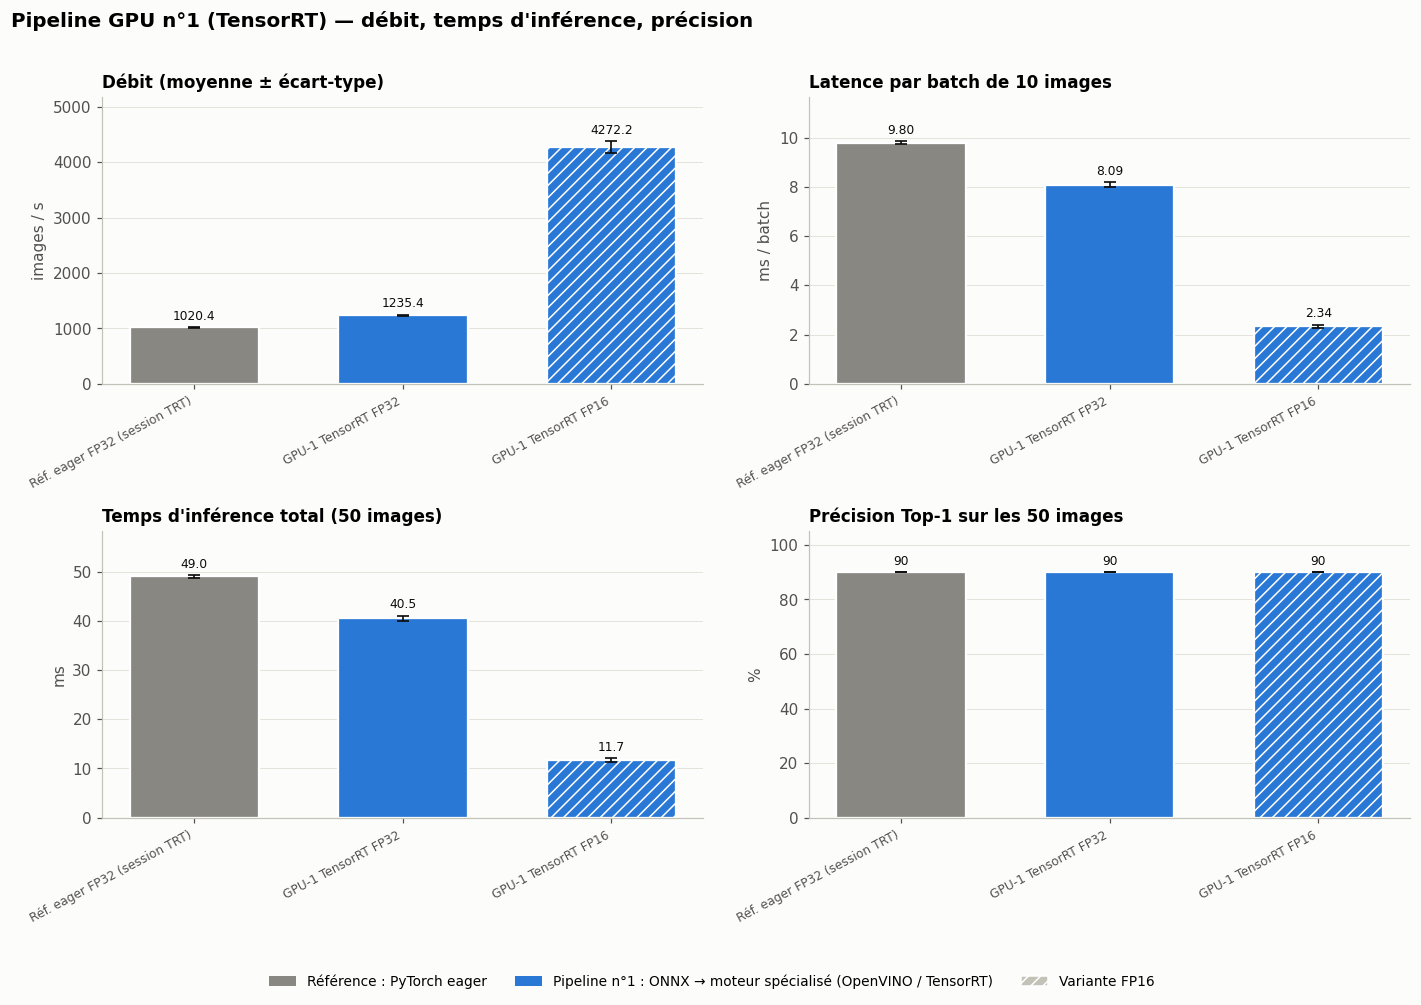

In [26]:
fig_performance(trt_results, "Pipeline GPU n°1 (TensorRT) — débit, temps d'inférence, précision", "trt_performance.png")

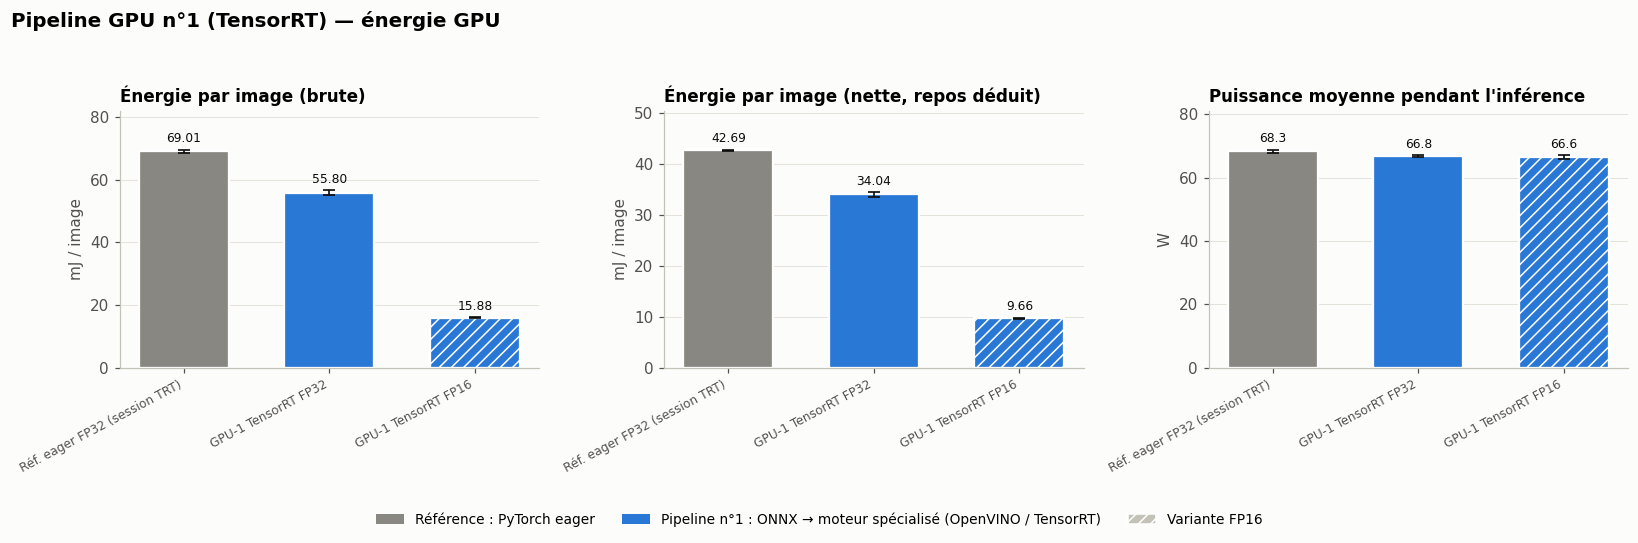

In [27]:
fig_energy(trt_results, "Pipeline GPU n°1 (TensorRT) — énergie GPU", "trt_energie.png")

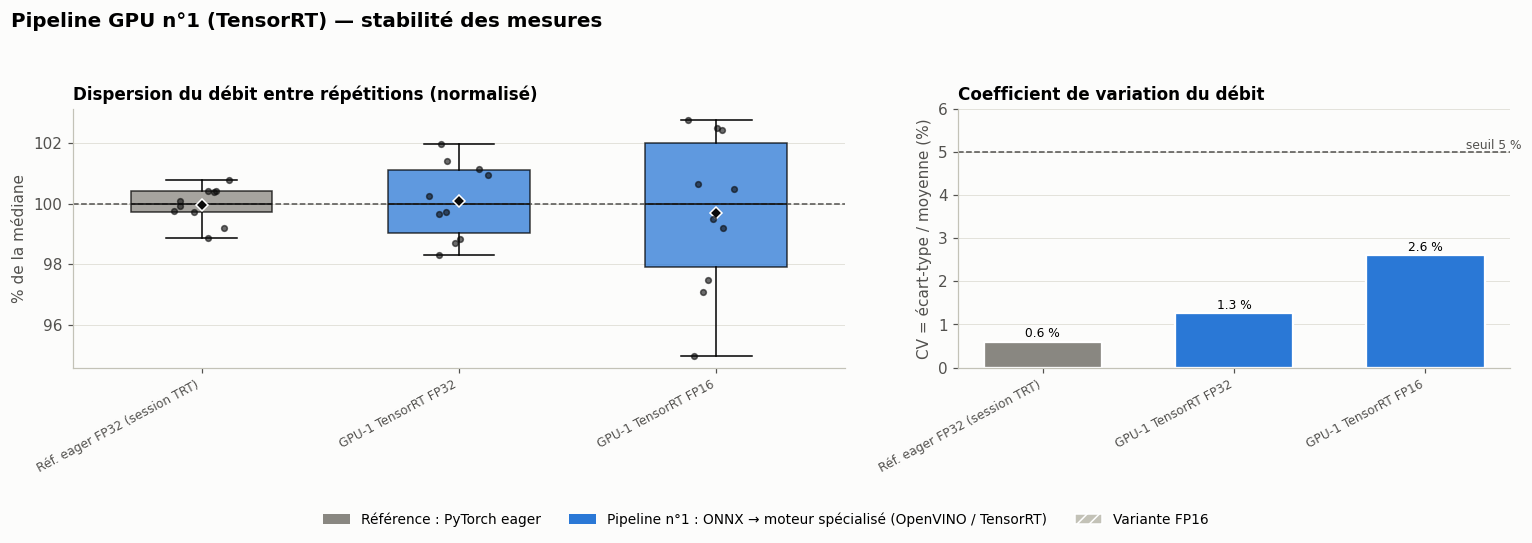

In [28]:
fig_variability(trt_results, "Pipeline GPU n°1 (TensorRT) — stabilité des mesures", "trt_variabilite.png")

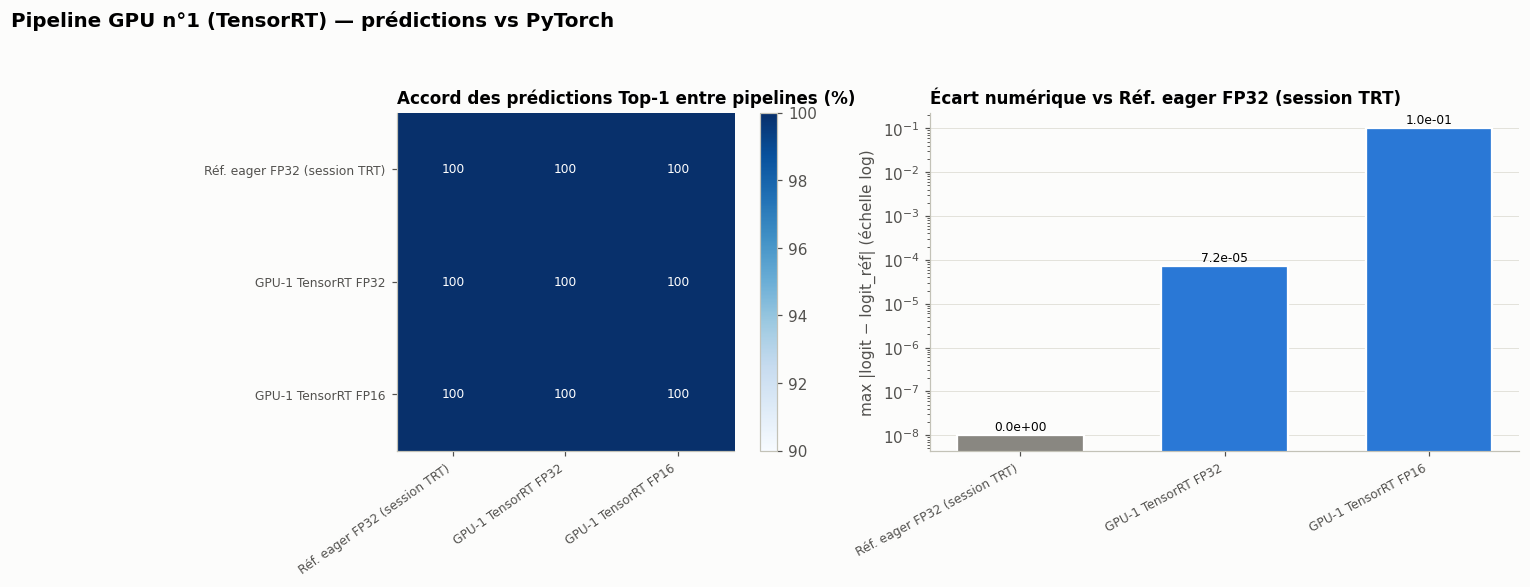

,accord_top1_vs_ref_%,max_|Δlogit|,moy_|Δlogit|,max_|Δproba|,top1_%
pipeline,,,,,
Réf. eager FP32 (session TRT),100.0,0.00e+00,0.00e+00,0.00e+00,90.0
GPU-1 TensorRT FP32,100.0,7.25e-05,9.58e-06,6.62e-06,90.0
GPU-1 TensorRT FP16,100.0,1.01e-01,2.11e-02,1.09e-02,90.0


In [29]:
df_agree_trt = fig_agreement(trt_results, SESSION_REF_KEY, "Pipeline GPU n°1 (TensorRT) — prédictions vs PyTorch",
                            "trt_predictions.png")
df_agree_trt

In [30]:
auto_comments(trt_results, SESSION_REF_KEY)

Référence : Réf. eager FP32 (session TRT) = 1020.4 img/s

- Réf. eager FP32 (session TRT) débit    1020.4 img/s  (× 1.00 vs réf.)  CV  0.6 %  [1009.1 ; 1029.0]  Top-1 90 %  E/img 69.01 mJ  → stable
- GPU-1 TensorRT FP32          débit    1235.4 img/s  (× 1.21 vs réf.)  CV  1.3 %  [1213.3 ; 1258.6]  Top-1 90 %  E/img 55.80 mJ  → stable
- GPU-1 TensorRT FP16          débit    4272.2 img/s  (× 4.19 vs réf.)  CV  2.6 %  [4069.5 ; 4402.5]  Top-1 90 %  E/img 15.88 mJ  → assez stable

Pipeline le plus rapide : GPU-1 TensorRT FP16
Précision Top-1 identique pour tous les pipelines : les optimisations ne dégradent pas les prédictions.


## 6. Comparaison des pipelines (section identique dans les 4 notebooks)

Cette section recharge **tous les résultats présents dans le dossier `results`** du Drive partagé : ceux des notebooks CPU (OpenVINO, TorchScript / torch.compile) et ceux des notebooks GPU (TensorRT, TorchScript / torch.compile). **Exécutez-la à la fin du dernier notebook lancé** pour obtenir la comparaison complète des 4 pipelines ; elle fonctionne aussi avec un seul pipeline disponible.

Chaque notebook Colab tourne sur **sa propre machine virtuelle** : on vérifie donc que les entrées et le batch sont identiques, et on présente l'**accélération par rapport à la référence eager mesurée dans la même session** (CPU → eager CPU, GPU → eager GPU). Les graphiques sont en échelle logarithmique dès qu'un résultat GPU est présent (écart d'un ou deux ordres de grandeur avec le CPU).

### Importer les résultats des notebooks CPU (envoyés par votre binôme)
Les notebooks CPU enregistrent leurs résultats dans leur propre dossier `results` (fichiers `*.json` et `*_logits.npy`, sous-dossier `history`). Demandez à votre binôme de vous envoyer ce dossier (zip, ou les fichiers), mettez `IMPORT_PARTNER_RESULTS = True` et sélectionnez-le : les fichiers sont copiés dans votre dossier `results`, puis la comparaison ci-dessous inclut les 4 pipelines. Sans import, elle compare seulement les pipelines GPU disponibles.

In [31]:
IMPORT_PARTNER_RESULTS = False
if IMPORT_PARTNER_RESULTS:
    import zipfile, io
    from google.colab import files

    def _store(relname, data):
        relname = relname.replace(chr(92), "/")
        base = os.path.basename(relname).split(" (")[0]
        if "shared/" in relname or "figures/" in relname or not (base.endswith(".json") or base.endswith("_logits.npy")):
            return
        dest = f"{RESULTS}/history/{base}" if "/history/" in "/" + relname or "__" in base else f"{RESULTS}/{base}"
        os.makedirs(os.path.dirname(dest), exist_ok=True)
        with open(dest, "wb") as f:
            f.write(data)
        print("  →", dest.replace(RESULTS, "results"))

    for name, data in files.upload().items():
        if name.endswith(".zip"):
            with zipfile.ZipFile(io.BytesIO(data)) as z:
                for member in z.namelist():
                    if not member.endswith("/"):
                        _store(member, z.read(member))
        else:
            _store(name, data)

In [32]:
CPU_KEYS = ["cpu_ov_ref_eager", "cpu1_openvino_fp32", "cpu1_openvino_int8",
            "cpu_pt_ref_eager", "cpu2_torchscript_fp32", "cpu2_compile_fp32", "cpu2_compile_freezing_fp32",
            "cpu2_compile_autotune_fp32"]
GPU_KEYS = ["gpu_trt_ref_eager", "gpu1_trt_fp32", "gpu1_trt_fp16",
            "gpu_pt_ref_eager", "gpu2_torchscript_fp32", "gpu2_compile_fp32", "gpu2_compile_freezing_fp32",
            "gpu2_compile_cudagraphs_fp32", "gpu2_compile_fp16", "gpu2_compile_autotune_fp32"]
REF_KEYS = ["cpu_ov_ref_eager", "cpu_pt_ref_eager", "gpu_trt_ref_eager", "gpu_pt_ref_eager"]

all_results = load_results(CPU_KEYS + GPU_KEYS)
cpu_all = {k: v for k, v in all_results.items() if v["platform"] == "CPU"}
has_gpu = any(v["platform"] == "GPU" for v in all_results.values())
REF_KEY = next(k for k in REF_KEYS if k in all_results)

if "cpu1_openvino_fp32" not in all_results:
    print("ℹ Pipeline CPU n°1 (OpenVINO) pas encore exécuté : lancez son notebook puis relancez cette section.")
if "cpu2_compile_fp32" not in all_results:
    print("ℹ Pipeline CPU n°2 (PyTorch) pas encore exécuté : lancez son notebook puis relancez cette section.")
if "gpu1_trt_fp32" not in all_results:
    print("ℹ Pipeline GPU n°1 (TensorRT) pas encore exécuté : lancez son notebook puis relancez cette section.")
if "gpu2_compile_fp32" not in all_results:
    print("ℹ Pipeline GPU n°2 (PyTorch) pas encore exécuté : lancez son notebook puis relancez cette section.")

cond = pd.DataFrame([{"pipeline": r["label"], "session": r.get("session_id"), "images": r["n_images"],
                      "batch": r["batch_size"], "warm-up": r["n_warmup"], "répétitions": r["n_runs"],
                      "SHA-256 entrées": r["test_sha256"][:12], "processeur": r["env"].get("cpu"),
                      "vCPU": r["env"].get("n_vcpu"), "GPU": r["env"].get("gpu", "—")}
                     for r in all_results.values()]).set_index("pipeline")
assert cond["batch"].nunique() == 1 and cond["images"].nunique() == 1, "Batch ou nombre d'images différent !"
if cond["SHA-256 entrées"].nunique() == 1:
    print("✔ Mêmes 50 images, même prétraitement, même batch pour tous les pipelines.")
else:
    # Les notebooks ont été exécutés séparément : chacun a recréé les 50 images avec le même code.
    # Les indices sont tirés avec la même graine ; seule l'interpolation flottante peut différer au dernier bit.
    idx = {tuple(r.get("extra", {}).get("test_indices", [])) for r in all_results.values() if r.get("extra", {}).get("test_indices")}
    print("⚠ Empreintes des entrées différentes :", dict(cond["SHA-256 entrées"].value_counts()))
    if len(idx) == 1:
        print("  Indices CIFAR-10 enregistrés par les notebooks GPU :", list(next(iter(idx))))
    print("  → comparez ces indices à ceux affichés en section 1 des notebooks CPU : s'ils sont identiques,"
          " ce sont les mêmes images (seul l'arrondi flottant du redimensionnement diffère).")
w = {r.get("extra", {}).get("weights_sha256", "")[:12] for r in all_results.values() if r.get("extra", {}).get("weights_sha256")}
if len(w) > 1:
    print("ℹ Poids recréés séparément (empreintes différentes) : les têtes 10 classes peuvent différer légèrement,"
          " d'où d'éventuels écarts de prédiction entre plateformes. Pour un modèle strictement identique,"
          " utilisez le même fichier resnet18_cifar10.pth partout (voir section 0).")
cpu_models = {r["env"].get("cpu") for r in cpu_all.values()}
if len(cpu_models) > 1:
    print("⚠ Les sessions CPU n'ont pas eu le même processeur :", cpu_models,
          "\n  → comparez surtout l'accélération vs eager de la même session, ou relancez pour obtenir le même CPU.")
gpu_models = {r["env"].get("gpu") for r in all_results.values() if r["platform"] == "GPU"}
if len(gpu_models) > 1:
    print("⚠ Les sessions GPU n'ont pas eu le même GPU :", gpu_models, "→ relancez avec le même type de GPU (T4).")
cond

ℹ Pipeline CPU n°1 (OpenVINO) pas encore exécuté : lancez son notebook puis relancez cette section.
ℹ Pipeline CPU n°2 (PyTorch) pas encore exécuté : lancez son notebook puis relancez cette section.
ℹ Pipeline GPU n°2 (PyTorch) pas encore exécuté : lancez son notebook puis relancez cette section.
✔ Mêmes 50 images, même prétraitement, même batch pour tous les pipelines.


,session,images,batch,warm-up,répétitions,SHA-256 entrées,processeur,vCPU,GPU
pipeline,,,,,,,,,
Réf. eager FP32 (session TRT),trt_20261125-163952,50,10,5,10,117a8d622a14,Intel(R) Xeon(R) CPU @ 2.00GHz,2,Tesla T4
GPU-1 TensorRT FP32,trt_20261125-163952,50,10,5,10,117a8d622a14,Intel(R) Xeon(R) CPU @ 2.00GHz,2,Tesla T4
GPU-1 TensorRT FP16,trt_20261125-163952,50,10,5,10,117a8d622a14,Intel(R) Xeon(R) CPU @ 2.00GHz,2,Tesla T4


In [33]:
df_all = summary_table(all_results)
df_all.to_csv(f"{RESULTS}/summary_all.csv")
pd.set_option("display.precision", 2); pd.set_option("display.max_columns", 40)
df_all

,plateforme,précision,débit moy (img/s),débit σ,débit min,débit max,débit CV %,latence batch moy (ms),latence σ,latence min,latence max,temps 50 img moy (ms),temps σ,temps min,temps max,Top-1 moy %,Top-1 σ,E/image moy (mJ),E/image σ,E nette/image (mJ),puissance moy (W),méthode énergie
pipeline,,,,,,,,,,,,,,,,,,,,,,
Réf. eager FP32 (session TRT),GPU,FP32,1020.38,6.11,1009.09,1028.96,0.60,9.80,0.06,9.72,9.91,49.00,0.29,48.59,49.55,90.0,0.0,69.01,0.49,42.69,68.31,NVML : compteur d'énergie de la carte GPU (mes...
GPU-1 TensorRT FP32,GPU,FP32,1235.41,15.48,1213.28,1258.61,1.25,8.09,0.10,7.94,8.24,40.48,0.51,39.73,41.21,90.0,0.0,55.80,0.75,34.04,66.83,NVML : compteur d'énergie de la carte GPU (mes...
GPU-1 TensorRT FP16,GPU,FP16,4272.19,111.20,4069.50,4402.47,2.60,2.34,0.06,2.27,2.46,11.71,0.31,11.36,12.29,90.0,0.0,15.88,0.21,9.66,66.55,NVML : compteur d'énergie de la carte GPU (mes...


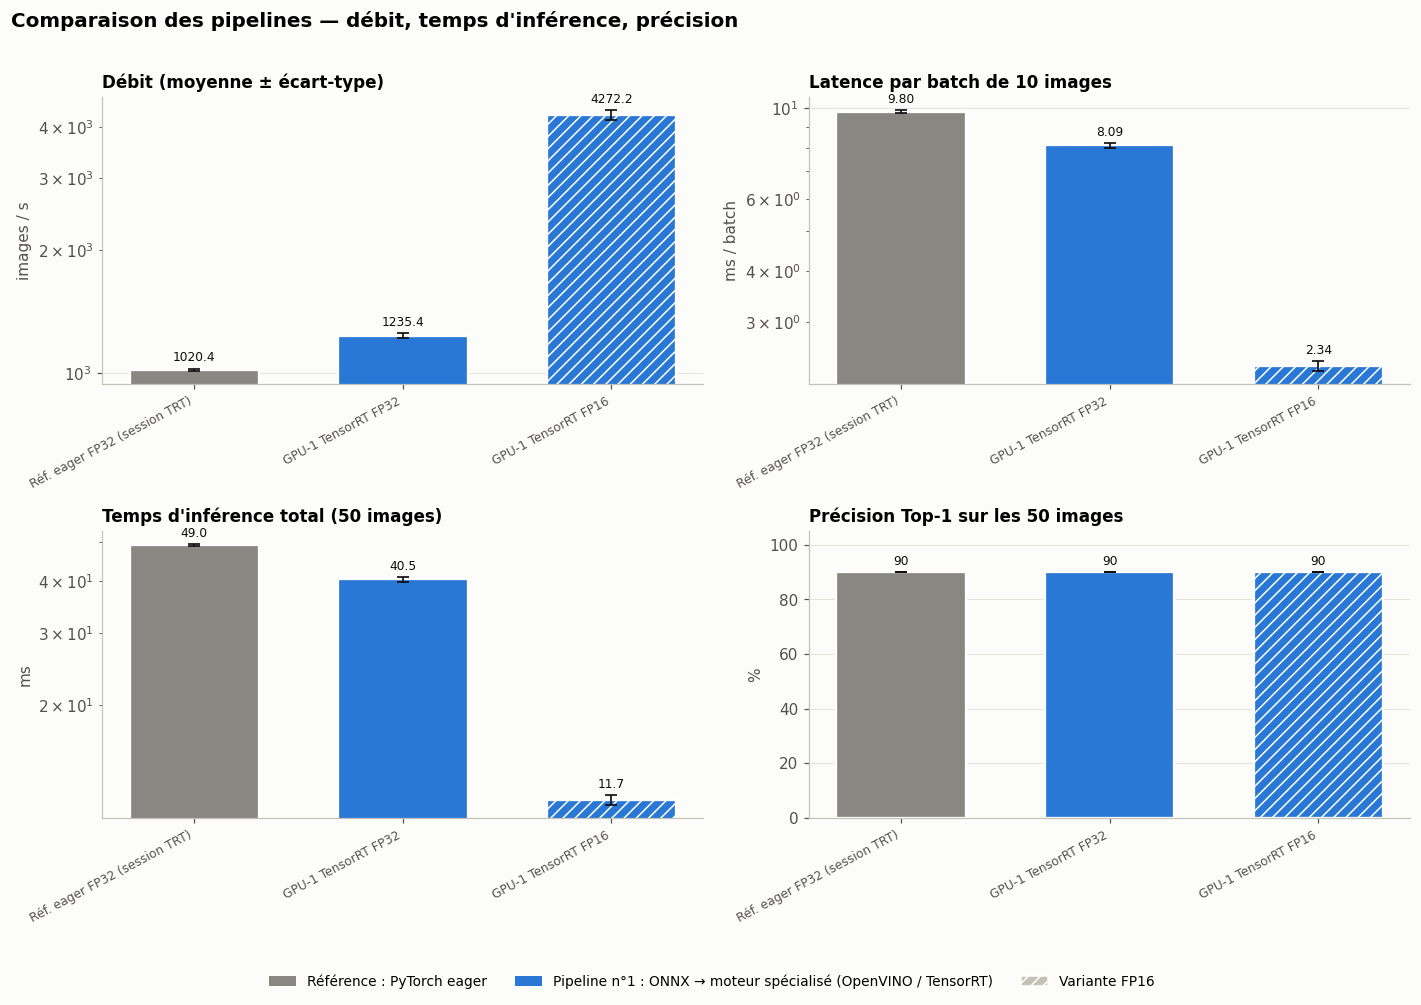

In [34]:
fig_performance(all_results, "Comparaison des pipelines — débit, temps d'inférence, précision",
                "compare_performance.png", log=has_gpu)

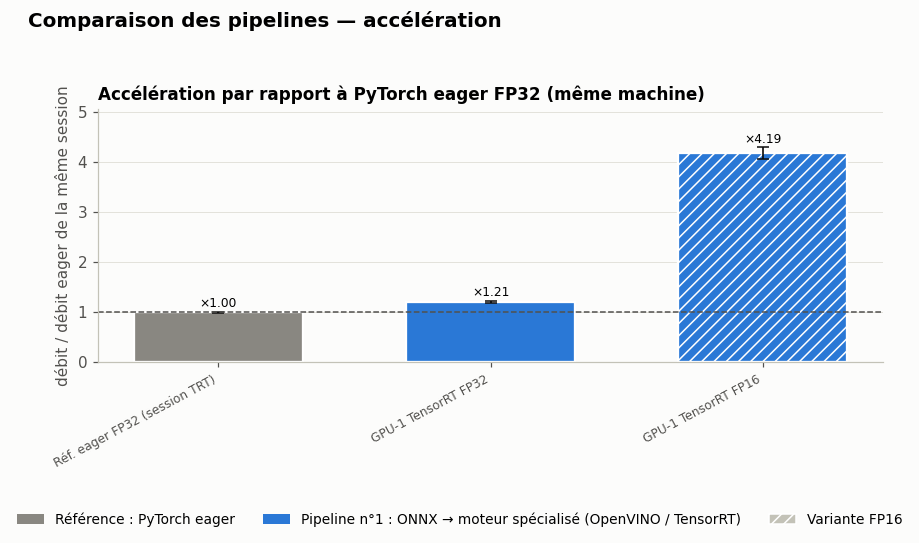

In [35]:
fig_speedup(all_results, "Comparaison des pipelines — accélération", "compare_acceleration.png")

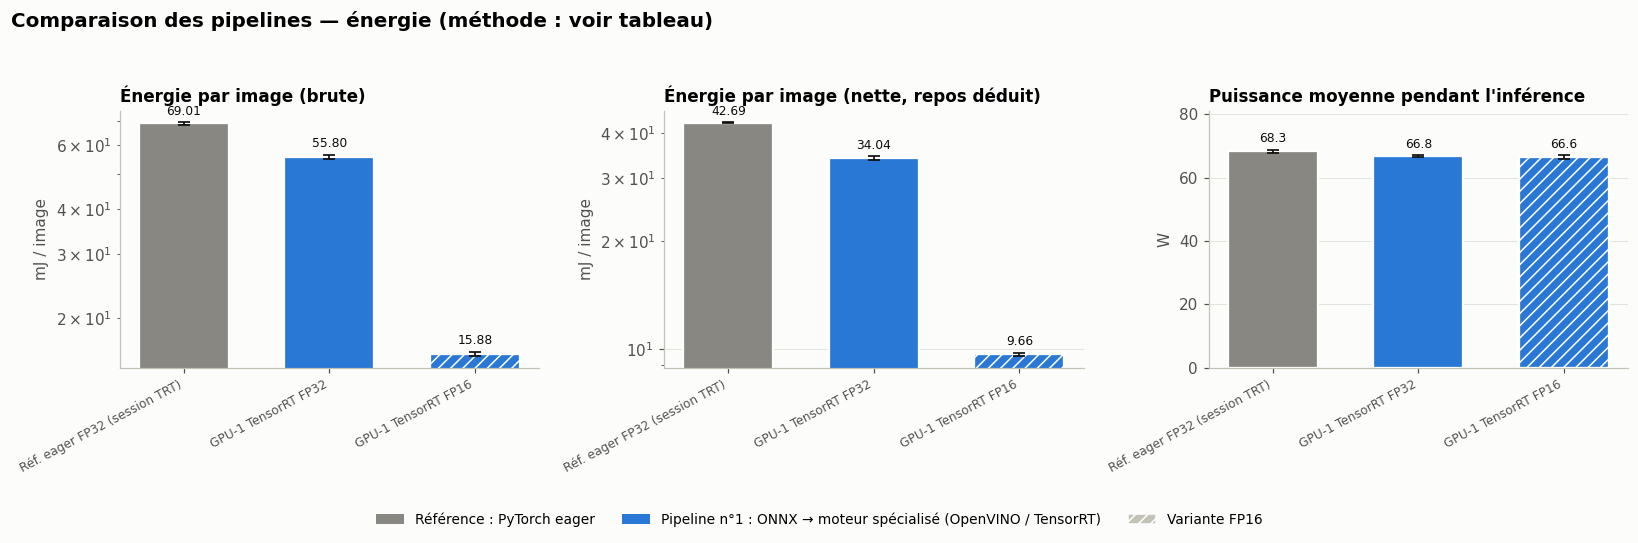

In [36]:
fig_energy(all_results, "Comparaison des pipelines — énergie (méthode : voir tableau)", "compare_energie.png", log=has_gpu)

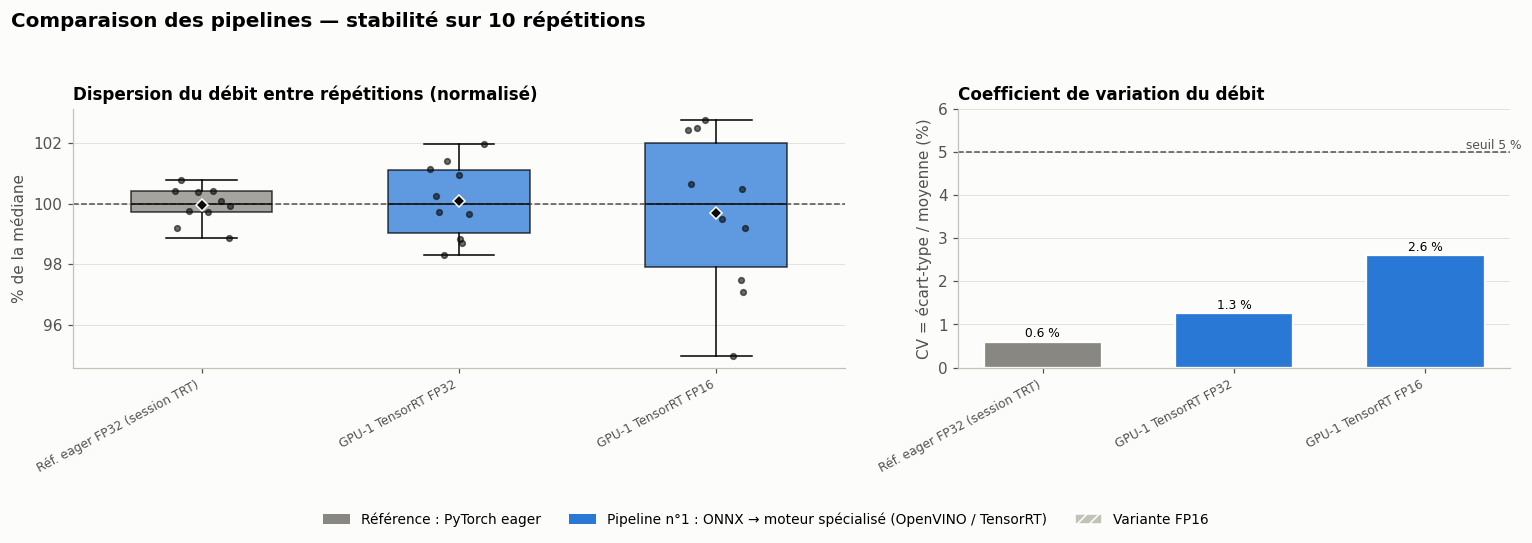

In [37]:
fig_variability(all_results, "Comparaison des pipelines — stabilité sur 10 répétitions", "compare_variabilite.png")

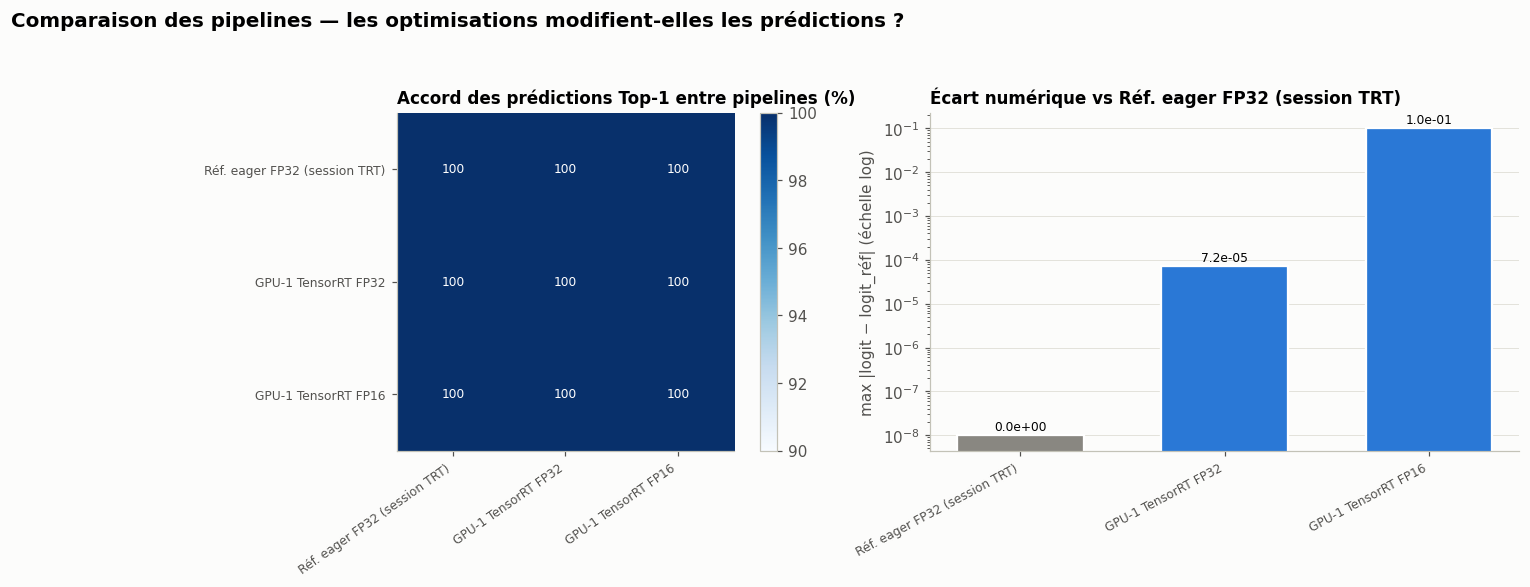

,accord_top1_vs_ref_%,max_|Δlogit|,moy_|Δlogit|,max_|Δproba|,top1_%
pipeline,,,,,
Réf. eager FP32 (session TRT),100.0,0.00e+00,0.00e+00,0.00e+00,90.0
GPU-1 TensorRT FP32,100.0,7.25e-05,9.58e-06,6.62e-06,90.0
GPU-1 TensorRT FP16,100.0,1.01e-01,2.11e-02,1.09e-02,90.0


In [38]:
df_agree = fig_agreement(all_results, REF_KEY, "Comparaison des pipelines — les optimisations modifient-elles les prédictions ?",
                         "compare_predictions.png")
df_agree

In [39]:
# Images dont la prédiction diffère entre pipelines
logits_all = {k: np.load(f"{RESULTS}/{k}_logits.npy") for k in all_results}
ref_pred = logits_all[REF_KEY].argmax(1)
diff_idx = sorted({int(i) for v in logits_all.values() for i in np.where(v.argmax(1) != ref_pred)[0]})
if not diff_idx:
    print("Aucune image ne change de classe prédite : tous les pipelines donnent les mêmes 50 prédictions.")
else:
    rows = []
    for i in diff_idx:
        row = {"image": i, "vraie classe": CLASSES[Y50_NP[i]]}
        row.update({all_results[k]["label"]: CLASSES[int(v[i].argmax())] for k, v in logits_all.items()})
        rows.append(row)
    display(pd.DataFrame(rows).set_index("image"))

Aucune image ne change de classe prédite : tous les pipelines donnent les mêmes 50 prédictions.


### Exécutions indépendantes (variabilité entre sessions)
Les 10 répétitions d'un même notebook ont lieu dans **une même session** (même machine, même processus). Pour mesurer la reproductibilité **entre exécutions indépendantes**, relancez chaque notebook dans une **nouvelle session** (`Exécution` → `Déconnecter et supprimer l'environnement d'exécution`, puis `Tout exécuter`) au moins **3 fois**. Chaque exécution ajoute une ligne par pipeline dans `results/history/`, et le tableau ci-dessous calcule moyenne, écart-type, min et max **entre sessions**.

In [40]:
hist_rows, hist_agg = history_table()
if hist_rows.empty:
    print("Aucun historique.")
else:
    display(hist_rows)
    display(hist_agg)
    hist_agg.to_csv(f"{RESULTS}/summary_inter_sessions.csv")
    multi = hist_agg[hist_agg["sessions"] >= 2]
    if len(multi):
        fig, ax = plt.subplots(figsize=(11, 4.5))
        for i, (lab, g) in enumerate(hist_rows.groupby("pipeline")):
            ax.scatter(np.full(len(g), i), g["débit (img/s)"], s=30, color="#2a78d6", zorder=3)
            ax.errorbar(i, g["débit (img/s)"].mean(), yerr=g["débit (img/s)"].std() if len(g) > 1 else 0,
                        fmt="D", color="#0b0b0b", capsize=5)
        ax.set_xticks(range(hist_rows["pipeline"].nunique()))
        ax.set_xticklabels(sorted(hist_rows["pipeline"].unique()), rotation=28, ha="right", fontsize=8)
        ax.set_ylabel("débit moyen de la session (img/s)")
        ax.set_title("Débit par session (points) et moyenne ± écart-type entre sessions", loc="left",
                     fontsize=11, fontweight="bold")
        ax.grid(axis="x", visible=False)
        fig.tight_layout(); fig.savefig(f"{FIGS}/inter_sessions.png", bbox_inches="tight"); plt.show()
    else:
        print("Une seule session par pipeline pour l'instant : relancez le notebook dans une nouvelle session.")

,pipeline,session,cpu,débit (img/s),latence batch (ms),Top-1 %
0,GPU-1 TensorRT FP16,trt_20261125-163952,Intel(R) Xeon(R) CPU @ 2.00GHz,4272.19,2.34,90.0
1,GPU-1 TensorRT FP32,trt_20261125-163952,Intel(R) Xeon(R) CPU @ 2.00GHz,1235.41,8.09,90.0
2,Réf. eager FP32 (session TRT),trt_20261125-163952,Intel(R) Xeon(R) CPU @ 2.00GHz,1020.38,9.80,90.0


,sessions,débit_moy,débit_σ_inter_sessions,débit_min,débit_max,latence_moy,latence_σ_inter_sessions,top1_moy,débit_CV_inter_%
pipeline,,,,,,,,,
GPU-1 TensorRT FP16,1,4272.19,NaN,4272.19,4272.19,2.34,NaN,90.0,NaN
GPU-1 TensorRT FP32,1,1235.41,NaN,1235.41,1235.41,8.09,NaN,90.0,NaN
Réf. eager FP32 (session TRT),1,1020.38,NaN,1020.38,1020.38,9.80,NaN,90.0,NaN


Une seule session par pipeline pour l'instant : relancez le notebook dans une nouvelle session.


In [41]:
auto_comments(all_results, REF_KEY)
print("\nFigures :", FIGS, "\nTableaux :", f"{RESULTS}/summary_all.csv")

Référence : Réf. eager FP32 (session TRT) = 1020.4 img/s

- Réf. eager FP32 (session TRT) débit    1020.4 img/s  (× 1.00 vs réf.)  CV  0.6 %  [1009.1 ; 1029.0]  Top-1 90 %  E/img 69.01 mJ  → stable
- GPU-1 TensorRT FP32          débit    1235.4 img/s  (× 1.21 vs réf.)  CV  1.3 %  [1213.3 ; 1258.6]  Top-1 90 %  E/img 55.80 mJ  → stable
- GPU-1 TensorRT FP16          débit    4272.2 img/s  (× 4.19 vs réf.)  CV  2.6 %  [4069.5 ; 4402.5]  Top-1 90 %  E/img 15.88 mJ  → assez stable

Pipeline le plus rapide : GPU-1 TensorRT FP16
Précision Top-1 identique pour tous les pipelines : les optimisations ne dégradent pas les prédictions.

Figures : /content/drive/MyDrive/TP_Deploiement_IA/figures 
Tableaux : /content/drive/MyDrive/TP_Deploiement_IA/results/summary_all.csv


### (Optionnel) Sans Google Drive : récupérer les fichiers pour les autres notebooks
Si `USE_DRIVE = False`, téléchargez l'archive et importez-la dans le notebook suivant (cellule équivalente au début).

In [42]:
if not USE_DRIVE:
    import shutil
    from google.colab import files
    shutil.make_archive("/content/TP_Deploiement_IA", "zip", ROOT)
    files.download("/content/TP_Deploiement_IA.zip")

### (Optionnel) Envoyer vos résultats GPU à votre binôme
Avec `EXPORT_RESULTS = True`, cette cellule crée `resultats_GPU.zip` (dossier `results` avec l'historique, et les figures). Votre binôme peut le déposer dans son dossier `TP_Deploiement_IA` (ou l'importer avec la cellule d'import ci-dessus si vous lui donnez ce notebook), remplacer sa cellule de clés par celle de ce notebook (section 6) et relancer sa section 6 pour obtenir la même comparaison des 4 pipelines.

In [43]:
EXPORT_RESULTS = False   # True : télécharge resultats_GPU.zip (dossier results + figures)
if EXPORT_RESULTS:
    import zipfile
    from google.colab import files
    ARCHIVE = "/content/resultats_GPU.zip"
    with zipfile.ZipFile(ARCHIVE, "w", zipfile.ZIP_DEFLATED) as z:
        for folder in (RESULTS, FIGS):
            for dirpath, _, filenames in os.walk(folder):
                for fn in filenames:
                    full = os.path.join(dirpath, fn)
                    z.write(full, os.path.relpath(full, ROOT))
    print(f"{ARCHIVE} : {os.path.getsize(ARCHIVE) / 1e6:.1f} Mo")
    files.download(ARCHIVE)

## Bilan de l'exécution

In [44]:
# ---------- Bilan de l'exécution ----------
ok = load_results()
print("Résultats enregistrés dans", RESULTS, ":")
for k, r in ok.items():
    if r["platform"] == "GPU" and r.get("session_id") == SESSION_ID:
        print(f"  ✔ {r['label']}")
if FAILED:
    print("\nVariantes ignorées pendant cette exécution (le reste du notebook a tourné normalement) :")
    for k, v in FAILED.items():
        print(f"  ✘ {k} : {v[:200]}")
else:
    print("\nAucune erreur : toutes les variantes ont été mesurées.")
print("Figures :", FIGS)

Résultats enregistrés dans /content/drive/MyDrive/TP_Deploiement_IA/results :
  ✔ GPU-1 TensorRT FP16
  ✔ GPU-1 TensorRT FP32
  ✔ Réf. eager FP32 (session TRT)

Aucune erreur : toutes les variantes ont été mesurées.
Figures : /content/drive/MyDrive/TP_Deploiement_IA/figures


## 7. Analyse — Pipeline GPU n°1 (PyTorch → ONNX → TensorRT) sur Tesla T4

*Environnement : Google Colab, Tesla T4 (Turing, sm 7.5, plafond 70 W), driver 580.82, PyTorch 2.14.1+cu130, CUDA 13.0, cuDNN 9.28, TensorRT 11.5.0.63, 2 vCPU Xeon 2,0 GHz. Protocole commun : 50 images CIFAR-10, batch 10, 5 passes de warm-up, 10 passes mesurées, 3 mesures d’énergie de 10 s. Chiffres de la session enregistrée dans le Drive ; une session précédente indépendante sert de contrôle de reproductibilité (partie D).*

| Variante | Débit (img/s) | Latence / batch (ms) | Accélération | Top-1 | Énergie / image brute – nette (mJ) | Puissance (W) | CV débit |
|---|---|---|---|---|---|---|---|
| PyTorch eager FP32 (réf.) | 1 020 ± 6 | 9,80 ± 0,06 | ×1,00 | 90 % | 69,0 – 42,7 | 68,3 | 0,6 % |
| TensorRT FP32 | 1 235 ± 15 | 8,09 ± 0,10 | ×1,21 | 90 % | 55,8 – 34,0 | 66,8 | 1,3 % |
| TensorRT FP16 | 4 272 ± 111 | 2,34 ± 0,06 | ×4,19 | 90 % | 15,9 – 9,7 | 66,6 | 2,6 % |

**A. Débit et temps d’inférence**

* **TensorRT FP32** atteint 1 235 img/s contre 1 020 img/s en eager : accélération de **×1,21** (latence par batch 9,80 → 8,09 ms, −17 %). Le gain est réel mais modeste, car en FP32 les deux moteurs utilisent la même famille de kernels cuDNN (convolutions Winograd et implicit GEMM) : la puissance de calcul disponible est la même.
* **Fusion d’opérateurs (4.3)** : les 49 nœuds ONNX (20 Conv, 17 Relu, 8 Add, MaxPool, GlobalAveragePool, Flatten, Gemm) deviennent **25 couches TensorRT** (20 CaskConvolution, 2 CaskPooling, 1 gemm, 1 Reformat, 1 NoOp). Toutes les ReLU et les 8 additions résiduelles ont disparu en tant que couches : elles sont exécutées dans l’épilogue du kernel de convolution, sans relire ni réécrire les activations en mémoire GPU. La BatchNorm avait déjà été repliée dans les poids des convolutions à l’export ONNX (constant folding) : le graphe ONNX ne contient aucun nœud BatchNormalization.
* **Kernels réellement exécutés (4.5)** : eager lance **106 kernels par batch** (20 distincts) pour 9,02 ms de temps GPU ; TensorRT FP32 n’en lance que **24** (12 distincts) pour 6,23 ms. Côté eager, on retrouve les opérations non fusionnées : 20 kernels de BatchNorm (`bn_fw_inf`, ≈ 0,80 ms/batch), 25 kernels élémentaires — exactement 17 ReLU + 8 Add (`vectorized_elementwise_kernel`, ≈ 1,04 ms/batch) — et 9 transformations de filtres Winograd recalculées à chaque appel (`winogradForwardFilter4x4`, ≈ 0,94 ms/batch). TensorRT supprime ces trois postes (≈ 2,8 ms/batch) : BN repliée, ReLU/Add fusionnées, poids transformés une fois pour toutes à la construction du moteur. Ses kernels dominants restent des convolutions cuDNN choisies par chronométrage des tactics sur ce T4 (`trt_volta_scudnn_winograd_128x128…`, 10 appels, ≈ 3,3 ms/batch).
* Le gain mesuré (×1,21) est plus faible que le rapport des temps GPU profilés (9,02 / 6,23 ≈ ×1,45). Une partie de la latence TensorRT (8,09 ms mesurés pour 6,23 ms de kernels) est du coût fixe : synchronisation CPU-GPU, passage des adresses, allocation de la sortie. Hypothèse complémentaire : pendant les boucles de mesure, la carte consomme 67 à 68 W, au plafond de 70 W du T4, et baisse sa fréquence, ce qui n’arrive pas pendant les 3 batches courts du profilage.
* **TensorRT FP16** : 4 272 img/s, soit **×4,19 par rapport à eager** et ×3,46 par rapport à TensorRT FP32 (2,34 ms par batch). Les kernels FP16 utilisent les **Tensor Cores** du T4 (`trt_turing_h1688cudnn…`, `sm75_xmma_fprop_implicit_gemm_f16f16…` : instructions HMMA 16×8×8 de Turing) et le temps GPU tombe à 1,87 ms/batch. Les poids et les activations pèsent moitié moins (moteur de 22,6 Mo contre 52,2 Mo en FP32) : deux fois moins d’octets à déplacer. Avec TensorRT 11, le FP16 est obtenu par un réseau « strongly typed » construit depuis un ONNX exporté en demi-précision.
* **Effet de la taille de batch (4.6)**, débit et latence d’un batch :

| Batch | PyTorch eager FP32 | TensorRT FP32 | TensorRT FP16 |
|---|---|---|---|
| 1 | 280 img/s (3,58 ms) | 663 img/s (1,51 ms) | 1 495 img/s (0,67 ms) |
| 10 | 893 img/s (11,20 ms) | 1 129 img/s (8,85 ms) | 4 054 img/s (2,47 ms) |
| 50 | 1 080 img/s (46,31 ms) | 1 157 img/s (43,21 ms) | 5 294 img/s (9,44 ms) |

  Au batch 1, TensorRT FP32 est **×2,4** plus rapide qu’eager : avec une seule image, le GPU est sous-utilisé et le temps est dominé par les coûts fixes (une centaine de lancements de kernels, dispatch Python opérateur par opérateur), que TensorRT réduit fortement. Au batch 50, l’écart FP32 n’est plus que de ×1,07 : le calcul domine et les deux moteurs utilisent des convolutions cuDNN comparables. Le débit FP16 continue d’augmenter jusqu’au batch 50 (×1,31 entre les batches 10 et 50), car les Tensor Cores ont besoin de beaucoup de travail en parallèle pour être saturés. La latence d’un batch augmente en revanche avec sa taille : c’est le compromis latence / débit.
* **Coûts de mise en place** : export ONNX en ≈ 1 s ; construction des moteurs en **7,4 s (FP32)** et **11,3 s (FP16)**, surtout pour chronométrer les tactics. Le moteur est lié au T4 (sm 7.5), à TensorRT 11.5 et à la forme d’entrée (batch 10) : il faut le reconstruire pour un autre GPU, une autre version ou un autre batch. Amortissement : TensorRT FP32 gagne 0,17 ms par image, il faut donc ≈ 43 000 images pour rembourser 7,4 s de construction ; FP16 gagne 0,75 ms par image, soit ≈ 15 000 images.

**B. Qualité des prédictions**

* **FP32** : écart maximal des logits **7,2·10⁻⁵** (moyen 9,6·10⁻⁶), accord Top-1 de **100 %** avec PyTorch et même Top-1 (90 %, soit 45/50). Les écarts viennent seulement de l’ordre des opérations flottantes et d’algorithmes de convolution différents.
* **FP16** : écart maximal des logits **1,0·10⁻¹** (moyen 2,1·10⁻²), environ 1 000 fois plus qu’en FP32 : la demi-précision n’a que 10 bits de mantisse. Malgré cela, **aucune prédiction ne change** : accord Top-1 de 100 % et Top-1 = 90 %, à tous les batches de l’étude 4.6.
* Les 5 erreurs sont les mêmes pour les trois variantes : images 4 (grenouille → oiseau), 6 et 40 (cerf → oiseau), 12 (oiseau → cerf) et 37 (automobile → navire). L’image 4 est un cas limite : lors de la session précédente, le moteur FP16 (autres tactics) l’avait classée correctement (Top-1 = 92 %). Sur 50 images, une image = 2 points : FP16 conserve la précision du modèle, à une image limite près selon le moteur construit.

**C. Énergie**

* Mesure par **NVML** : compteur d’énergie de la carte GPU (valeur **mesurée**, carte seule). Puissance au repos : 26,1 W.
* La puissance moyenne en charge est presque la même pour les trois variantes (68,3 W eager, 66,8 W TRT FP32, 66,6 W TRT FP16, toutes proches du plafond de 70 W). L’énergie par image suit donc le temps par image (**E ≈ P × t**) : eager 68,3 W × 0,980 ms ≈ 67 mJ (mesuré : 69,0 mJ) ; FP16 66,6 W × 0,234 ms ≈ 15,6 mJ (mesuré : 15,9 mJ).
* Énergie brute par image : 69,0 mJ en eager → **55,8 mJ en TensorRT FP32 (−19 %)** → **15,9 mJ en FP16 (−77 %, ÷4,3)**. En énergie nette (repos déduit) : 42,7 → 34,0 → 9,7 mJ. À puissance égale, aller plus vite revient à consommer moins par image : le gain énergétique est du même ordre que le gain de débit.
* Limites : seule la carte GPU est mesurée (ni le CPU hôte qui pilote le GPU, ni la RAM). Dans les notebooks CPU, l’énergie est le plus souvent **estimée** (RAPL rarement accessible sur Colab, hypothèse de 10 W par vCPU actif) : toute comparaison CPU / GPU doit le préciser et rester prudente.

**D. Stabilité et reproductibilité**

* CV du débit : 0,6 % (eager) et 1,3 % (TensorRT FP32) → **très stables** ; 2,6 % en FP16 → **variabilité modérée** (entre 2 et 5 %). Les mesures d’énergie ont un CV inférieur à 1,4 %.
* FP16 est plus variable car un batch ne dure que 2,3 ms : les coûts fixes et la gigue de synchronisation CPU-GPU pèsent relativement plus, et la fréquence du GPU varie avec la puissance et la température.
* Intervalles [min ; max] du débit : eager [1 009 ; 1 029], TRT FP32 [1 213 ; 1 259], TRT FP16 [4 069 ; 4 402] → **aucun chevauchement** : les différences entre variantes dépassent largement le bruit de mesure.
* **Entre deux sessions indépendantes** (autre compte Colab, autre machine T4) : eager 1 019 → 1 020 img/s, TRT FP32 1 254 → 1 235 img/s (−1,5 %), TRT FP16 4 284 → 4 272 img/s (−0,3 %) ; énergie par image 69,0 → 69,0, 56,1 → 55,8 et 16,0 → 15,9 mJ. Les résultats sont **reproductibles à moins de 2 % près** et les conclusions ne changent pas.
* En revanche, l’étude 4.6 refait le batch 10 (5 répétitions) et obtient des débits 5 à 13 % plus bas (893 / 1 129 / 4 054 img/s) que les mesures principales : l’état du GPU (fréquence, température après les mesures précédentes) influe davantage que le CV intra-mesure ne le laisse croire. Il ne faut donc pas conclure sur des écarts de quelques pourcents entre configurations mesurées à des moments différents.

**E. Conclusion**

Sur le T4, la chaîne PyTorch → ONNX → TensorRT conserve exactement les prédictions en FP32 et apporte **×1,21 en débit et −19 % d’énergie par image**, grâce à la fusion des couches (106 → 24 kernels par batch) et au choix des tactics. Le vrai levier est le **FP16 sur Tensor Cores : ×4,2 en débit, 2,3 ms par batch, ÷4,3 en énergie par image**, sans aucune prédiction modifiée sur les 50 images. Ces résultats sont reproductibles d’une session à l’autre. Le prix à payer est la construction du moteur (7 à 11 s), à refaire pour chaque GPU, version de TensorRT et taille de batch : TensorRT est rentable pour un modèle déployé et beaucoup utilisé, pas pour quelques inférences ponctuelles. La comparaison avec les pipelines CPU (section 6) sera complète une fois les résultats du binôme importés.